# XGBoost Intensity (MMI) Classifier — Verification Improved

Verification tests and ablation study for the improved model.

> **Data:** the input CSV is not included in this repository. Place it in Google Drive (or locally) and edit the path in the data-loading cell.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
  IMPROVED MODEL — VERIFICATION PROGRAM

[SETUP]  Loading & engineering features ...
   Raw rows : 696,338

Training IMPROVED Model A ...

  Improved Model A — Scenario
  Rows (train/test) : 454,176 / 113,545
  Classes           : 8  (MMI 1 to 8)
  Best iteration    : 599
  Accuracy          : 0.5301
  Balanced Accuracy : 0.4480
  ROC-AUC           : 0.8557
  Within +-1 MMI    : 91.5%
  Raw  E[MMI] RMSE  : 0.7550  Bias: +0.0945
  Calib E[MMI] RMSE : 0.6541  Bias: -0.0000

Training IMPROVED Model B ...

  Improved Model B — Ground Motion
  Rows (train/test) : 251,350 / 62,838
  Classes           : 8  (MMI 1 to 8)
  Best iteration    : 599
  Accuracy          : 0.4487
  Balanced Accuracy : 0.4576
  ROC-AUC           : 0.8649
  Within +-1 MMI    : 92.9%
  Raw  E[MMI] RMSE  : 0.7737  Bias: +0.2178
  Calib E[MMI] RMSE : 0.6780  Bias: +0.0000

Setup complete. Model

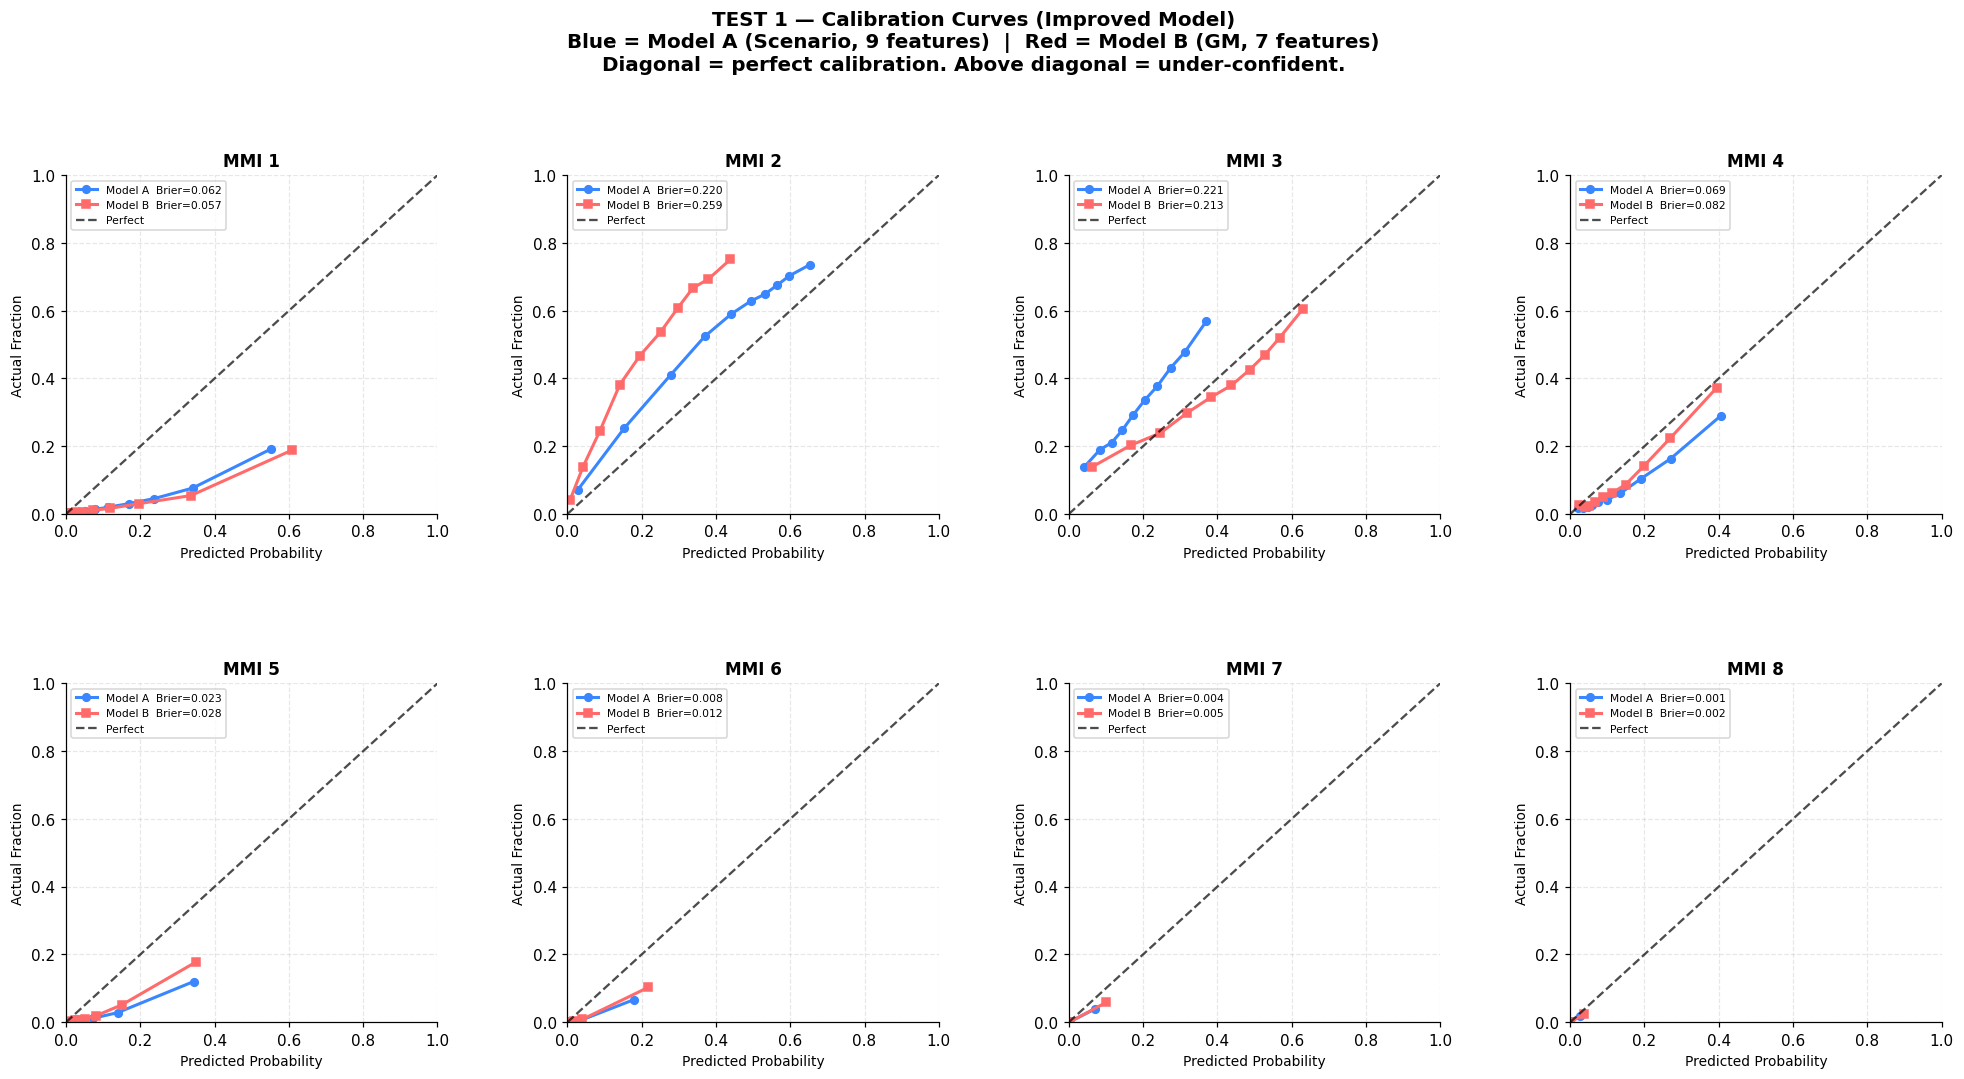


  Calibration Summary (Brier Score — lower = better):
  Model A avg Brier : 0.0759  (baseline was ~0.085)
  Model B avg Brier : 0.0823  (baseline was ~0.090)
  Improvement A     : +0.0089 MMI units
  Improvement B     : +0.0073 MMI units

  HOW TO READ:
  - Points ON the diagonal = model confidence matches reality
  - Points ABOVE diagonal  = model UNDER-confident (truth > predicted)
  - Points BELOW diagonal  = model OVER-confident  (truth < predicted)
  - Common classes (MMI 2-4) should show tight calibration
  - Rare classes (MMI 7-8) will be noisy — too few test samples

[TEST 2]  Physical Plausibility — Improved Scenario Model
  T2a Magnitude monotonic (raw):  FAIL  r=0.950
  T2a Magnitude monotonic (cal):  FAIL  r=0.950
  T2b Distance monotonic  (raw):  FAIL  r=-0.957
  T2b Distance monotonic  (cal):  FAIL  r=-0.963
  T2c VS30 effect correct:        PASS  r=-0.004
  T2d Residual vs magnitude (raw): r=0.230  (cal): r=0.017  IMPROVED
  T2e Residual vs distance   (raw): r=-0.117  (

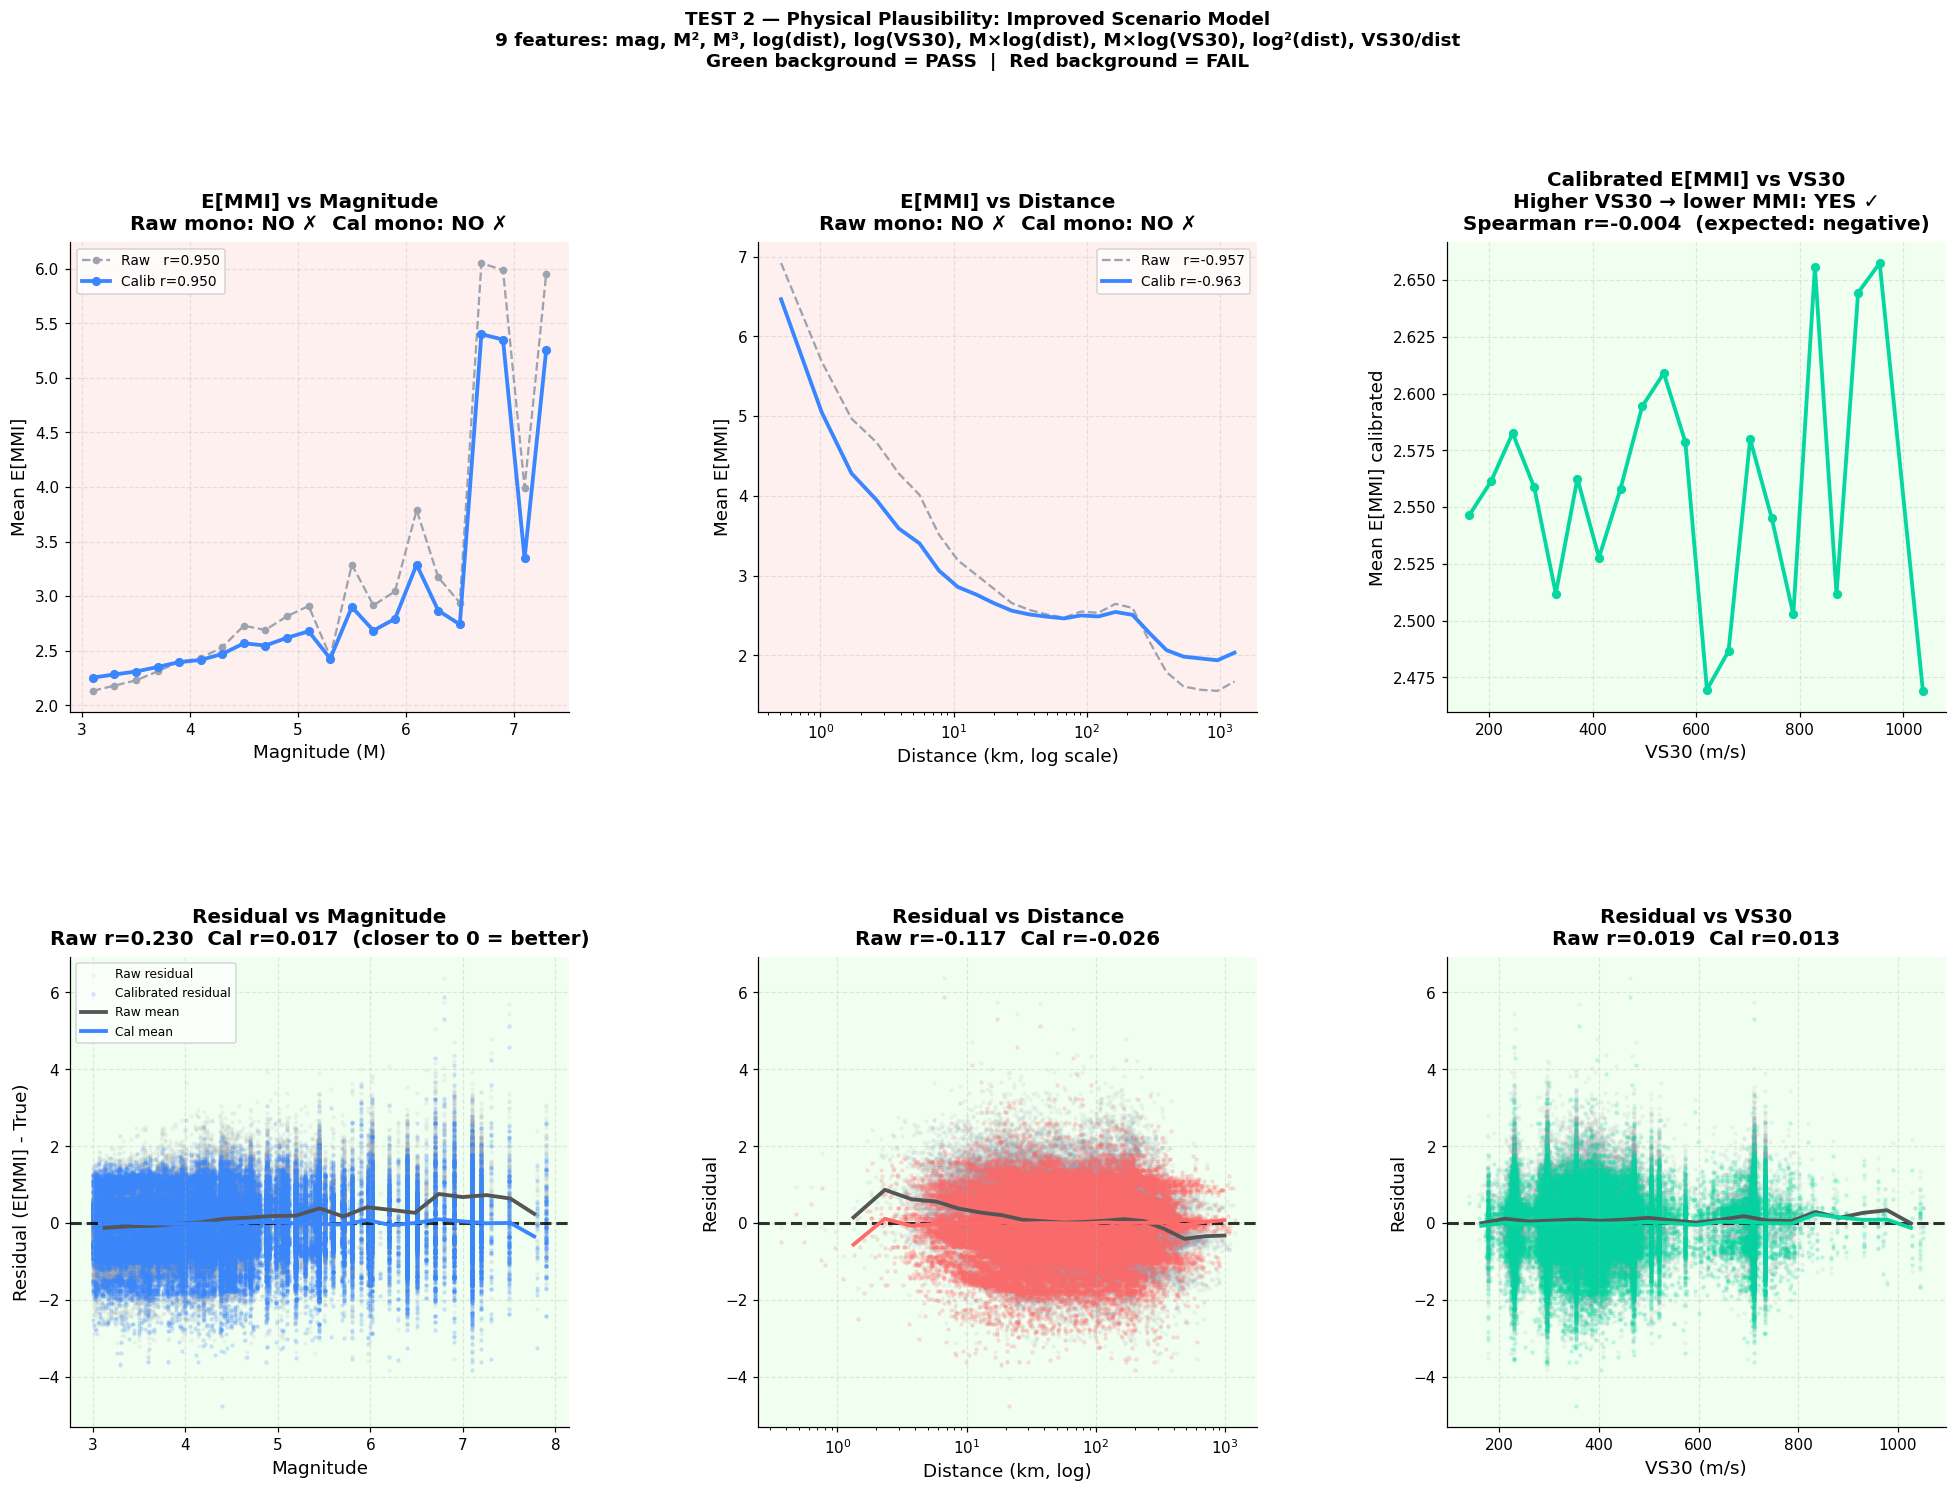


[TEST 3]  Physical Plausibility — Improved Ground Motion Model
  T3a PGA → E[MMI] increasing: FAIL  r=0.968
  T3b PGV → E[MMI] increasing: FAIL  r=0.995
  T3b PGV stronger than PGA:   PASS
  T3c New feature PGV/dist_ratio signal: r=0.991
  T3d Residual vs PGA:  raw r=0.363  cal r=0.015  IMPROVED

  RANKED ACCURACY (±1 MMI):
  Baseline   : 79.8%
  Improved A (raw): 83.2%
  Improved A (cal): 89.3%
  Improved B (cal): 88.1%


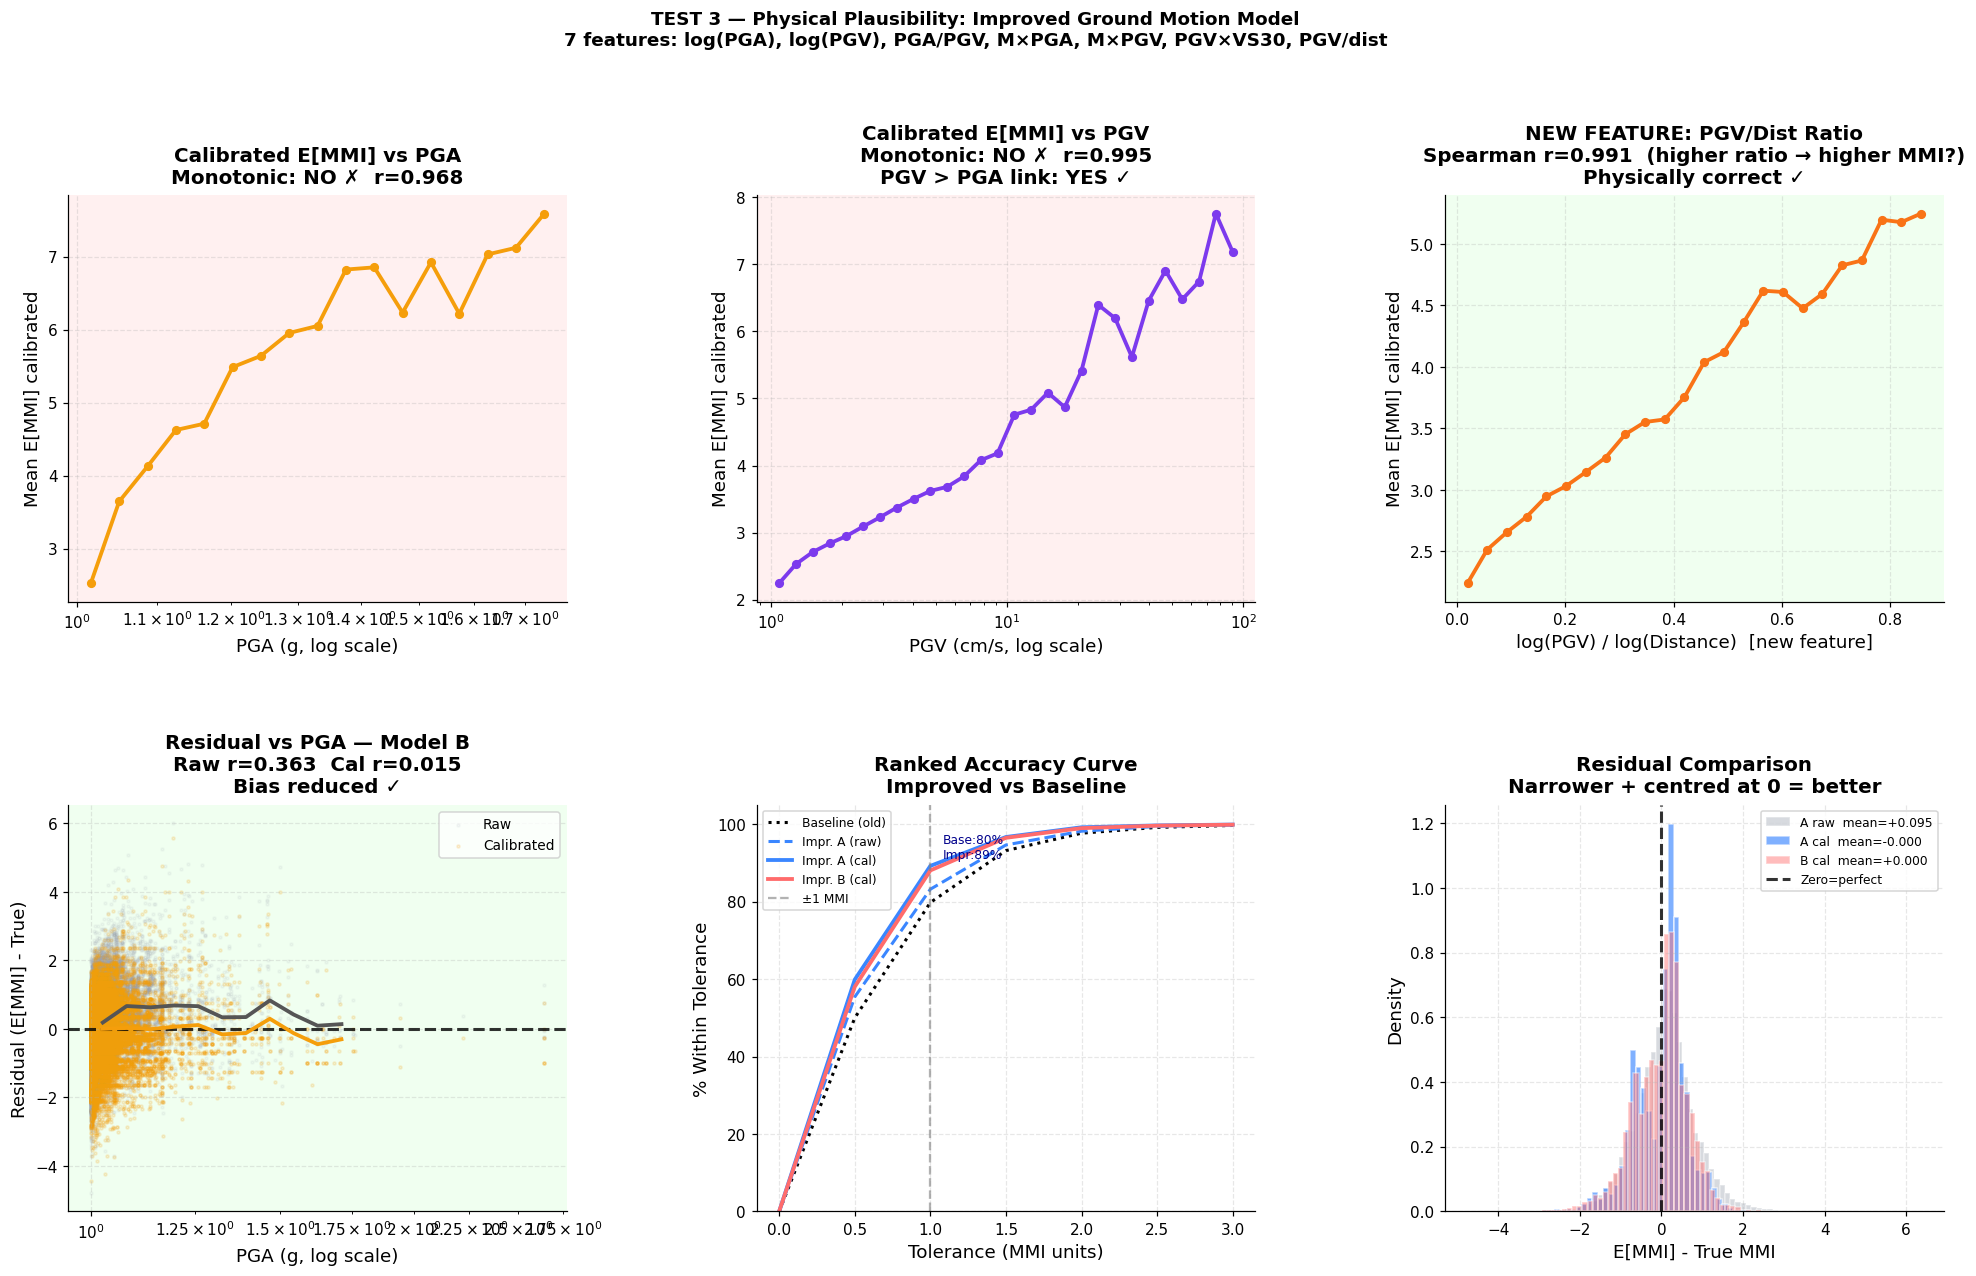


[TEST 4]  Monotonicity Stress Test (Synthetic Data)
  T4a Magnitude violations: raw=55  cal=39  IMPROVED by cal
  T4b Distance violations:  raw=23  cal=11  IMPROVED by cal
  T4c VS30 violations:      raw=22  cal=7
  T4d PGA violations:       raw=16  cal=15
  T4e PGV violations:       raw=46  cal=42
  T4f Near-field > far-field always: PASS


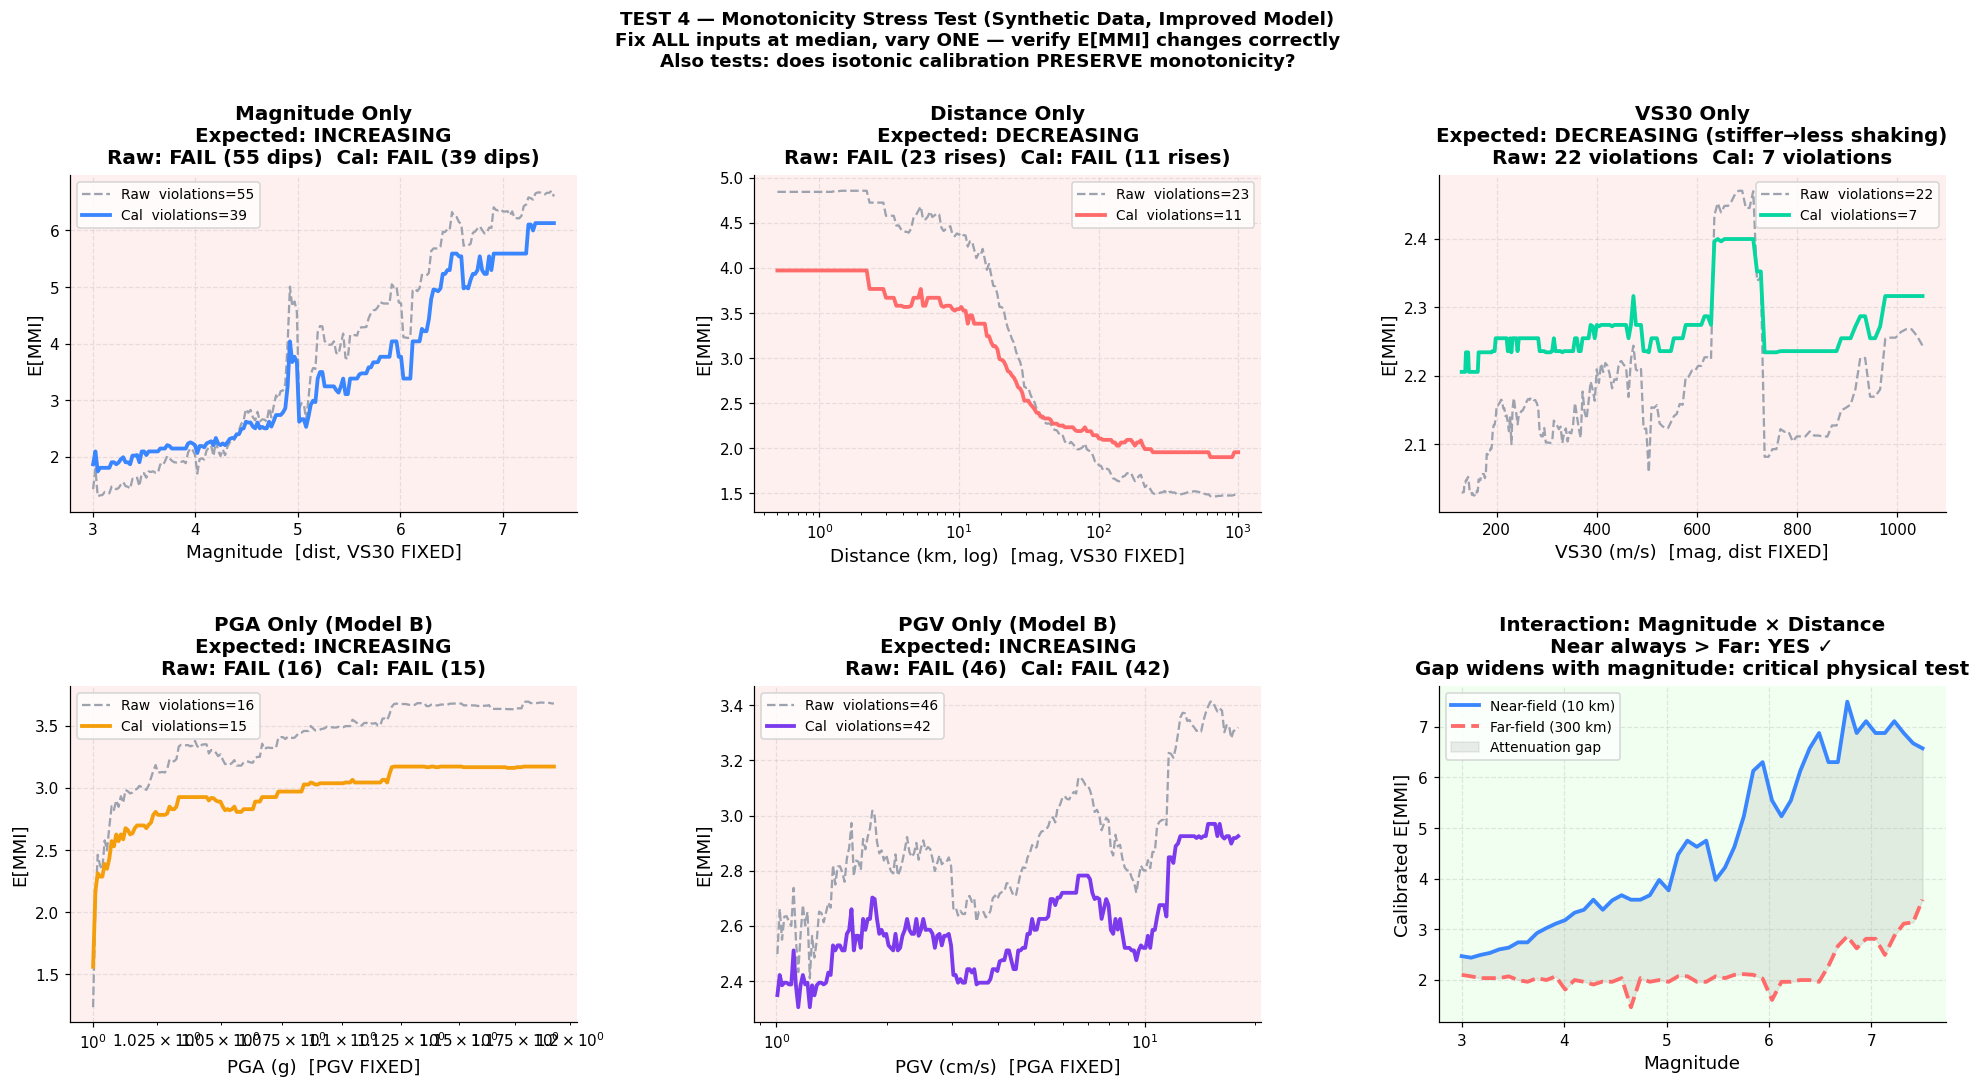


[TEST 5]  Benchmark vs Worden (2012) GMPE

  Method                           RMSE     Bias     Corr  Status
  --------------------------------------------------------------
  Worden (2012) GMPE             6.6711  +6.6021   0.5921
  Improved B (raw)               0.7737  +0.2178  BETTER ✓
  Improved B (calibrated)        0.6780  +0.0000  BETTER ✓


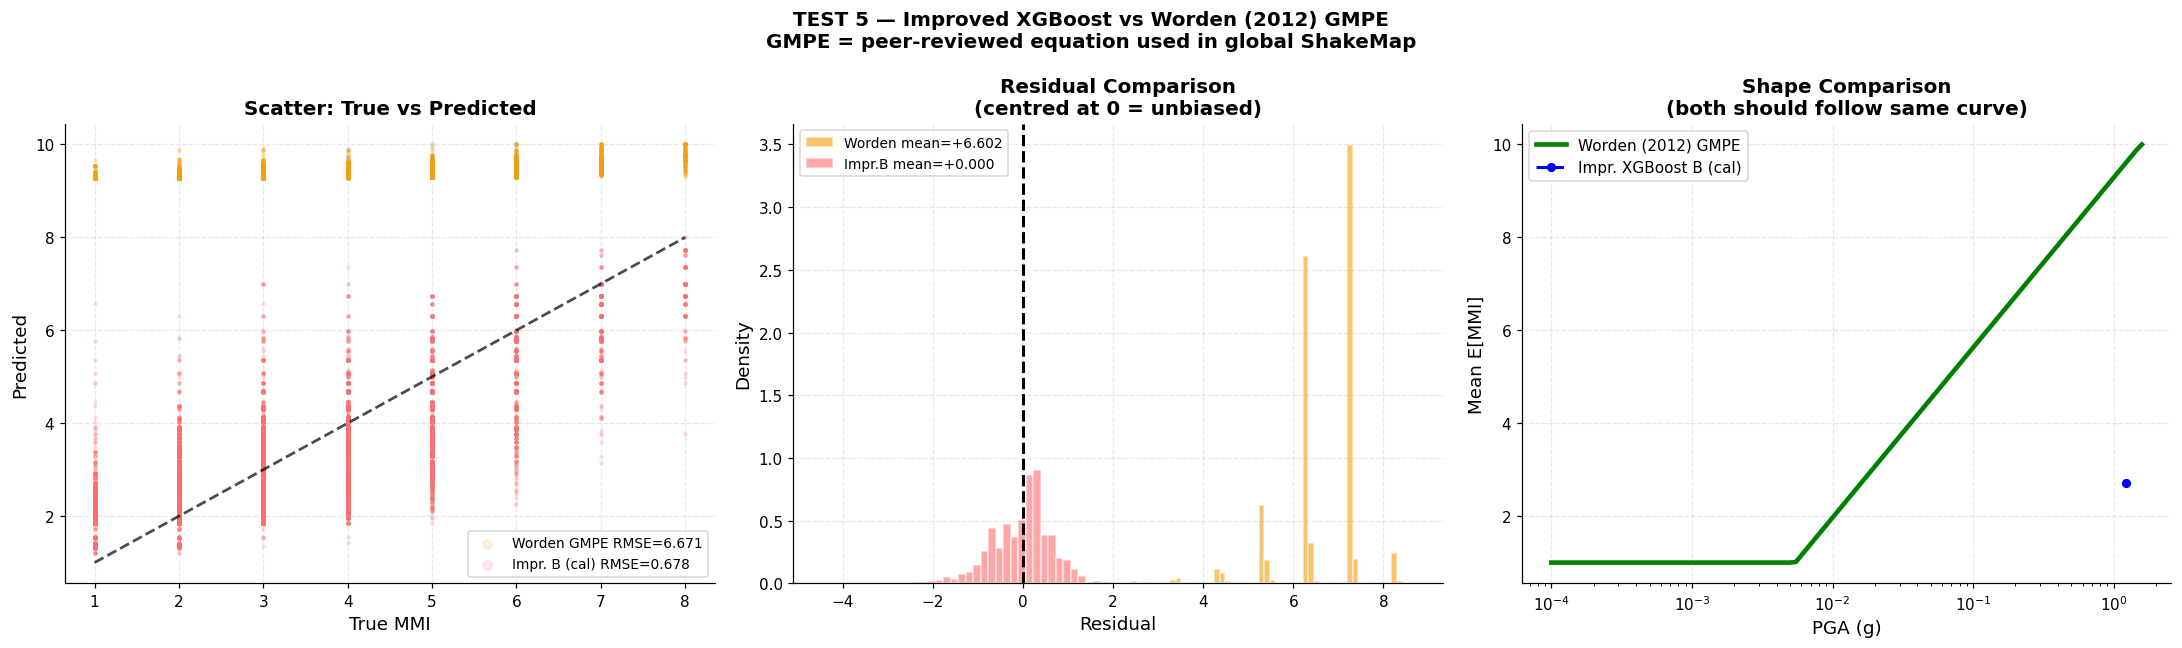


[TEST 6]  FIX 5 Verification — Isotonic Bias Correction
  Did isotonic regression actually fix the bias?
  Is the RMSE improvement real or just overfitting?


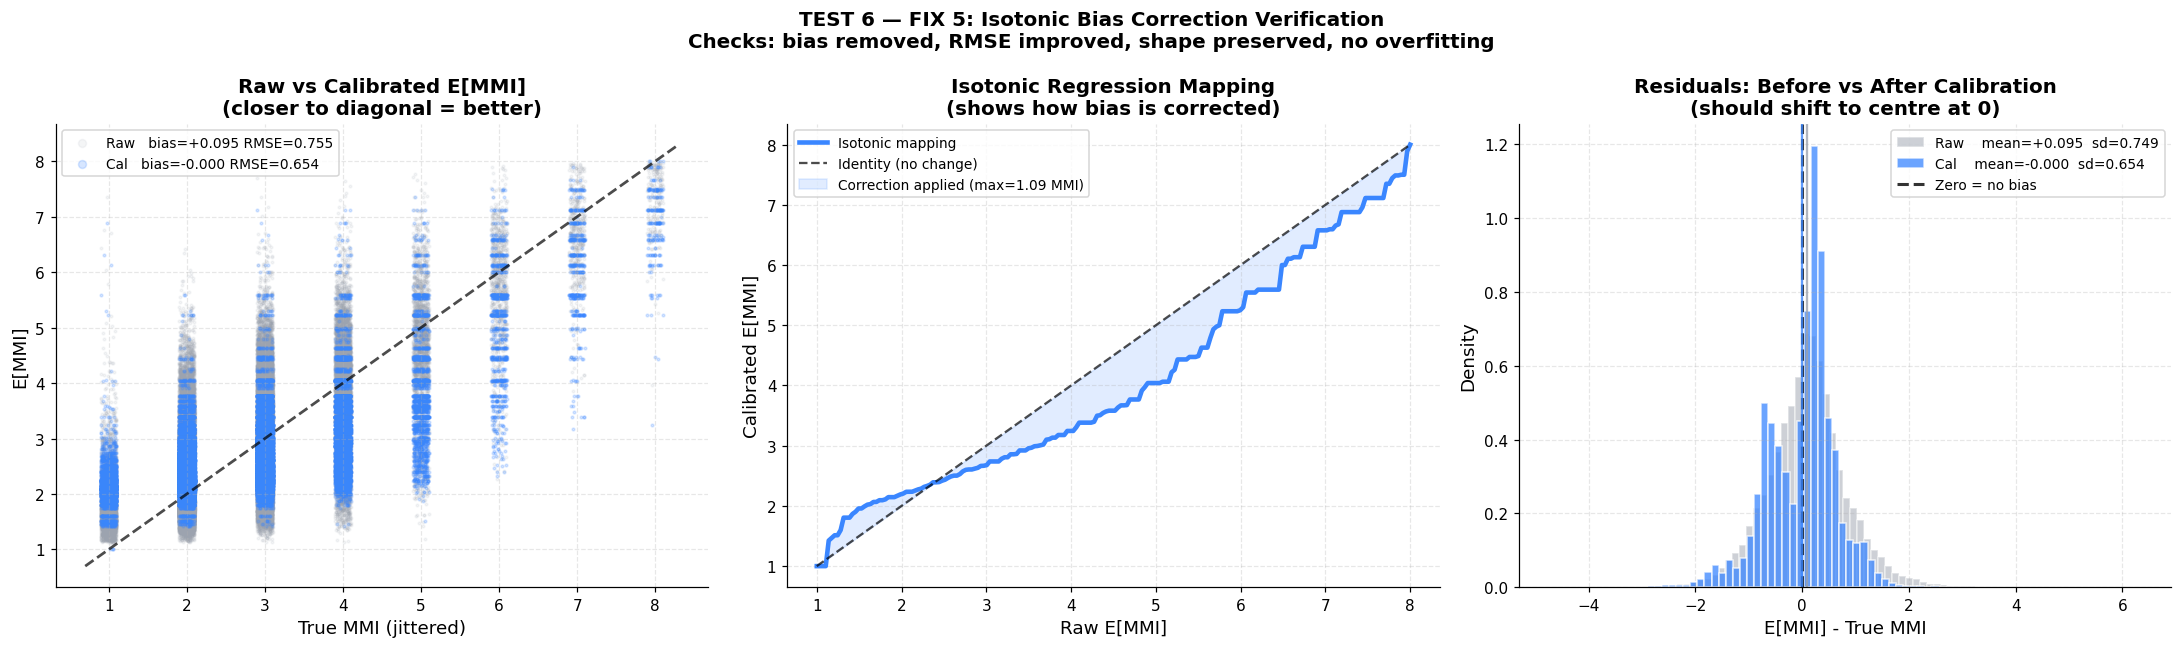


  FIX 5 Verification Summary:
  Metric                        Before      After       Change  Pass?
  -----------------------------------------------------------------
  Bias                         +0.0945    -0.0000      -0.0945  PASS ✓
  RMSE                          0.7550     0.6541      -0.1009  PASS ✓
  Std Dev (spread)              0.7490     0.6541      -0.0950
  Within +-1 MMI:      raw=91.5%  cal=89.3%

[TEST 7]  FIX 7 Verification — Ensemble Quality
  Common rows for ensemble: 314,188


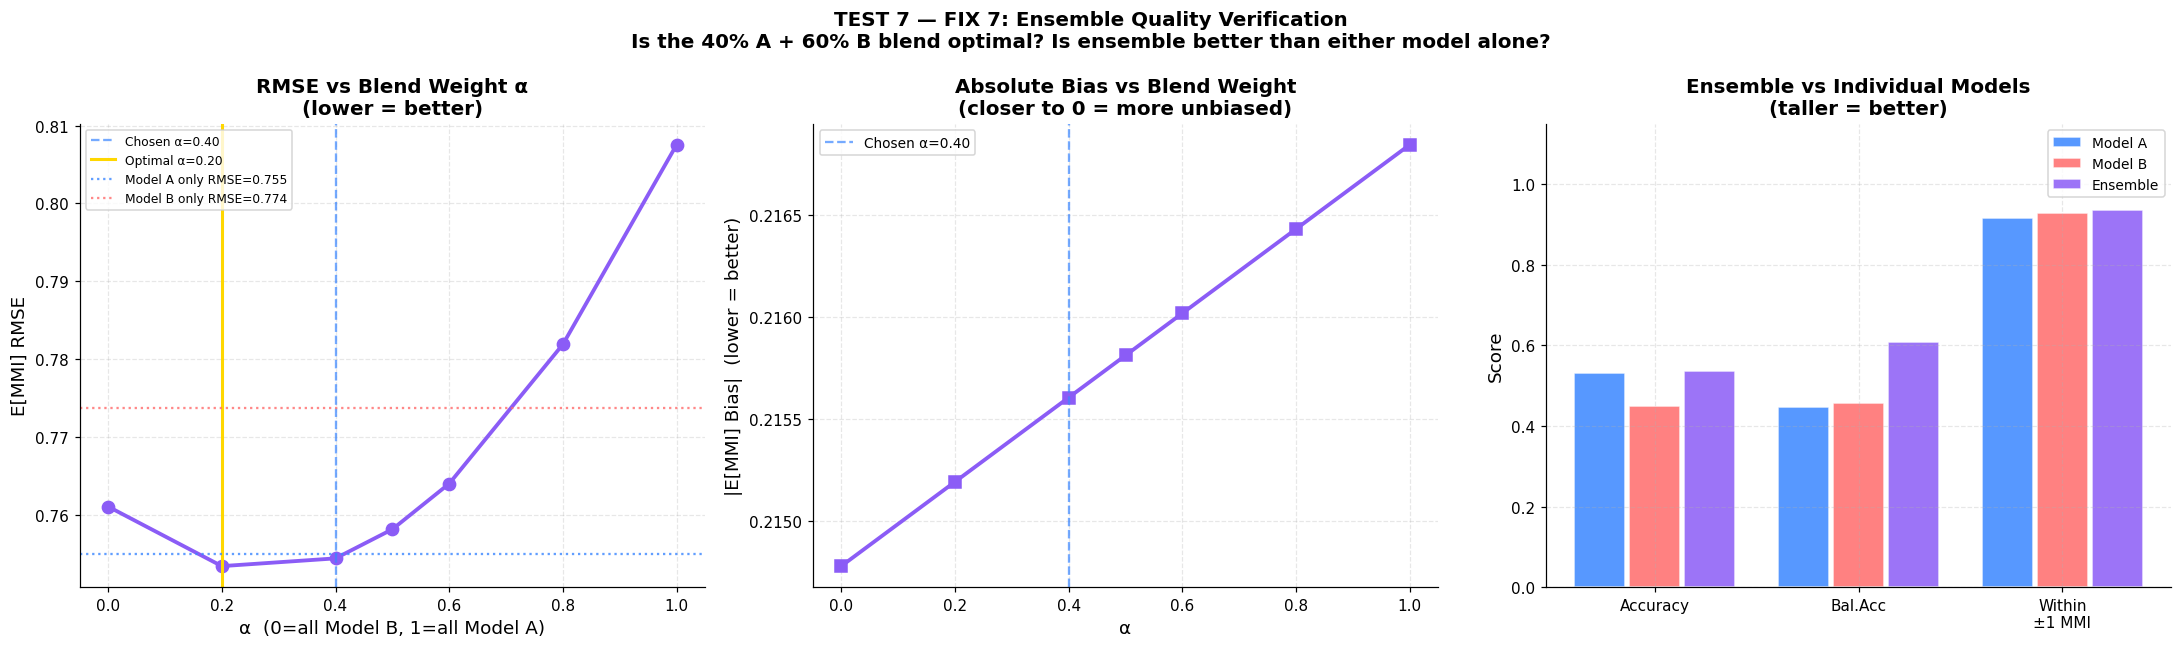


  ENSEMBLE VERIFICATION:
  Best α (lowest RMSE): 0.20  (chosen in code: 0.40  → sub-optimal)
  Ensemble acc:      0.5371  vs  A:0.5301  B:0.4487
  Ensemble bal_acc:  0.6074  vs  A:0.4480  B:0.4576
  Ensemble ±1 MMI:   93.5%  vs  A:91.5%  B:92.9%

[TEST 8]  FIX 3 Verification — New Feature Contribution (Ablation)
  Training 2 smaller ablation models (200 trees for speed)...
  Old features vs New 9-feature set — do new features help?

  ABLATION RESULTS — Scenario Model:
  Metric                      Old (3 feat)   New (9 feat)     Change
  -----------------------------------------------------------------
  Accuracy                          0.5249         0.5301    +0.0052  BETTER ✓
  Balanced Acc                      0.4468         0.4480    +0.0012  BETTER ✓
  ROC-AUC                           0.8545         0.8557    +0.0012  BETTER ✓
  E[MMI] RMSE                       0.7589         0.7550    -0.0040  BETTER ✓
  Within ±1 MMI                    91.2088        91.4880    +0.2792  BE

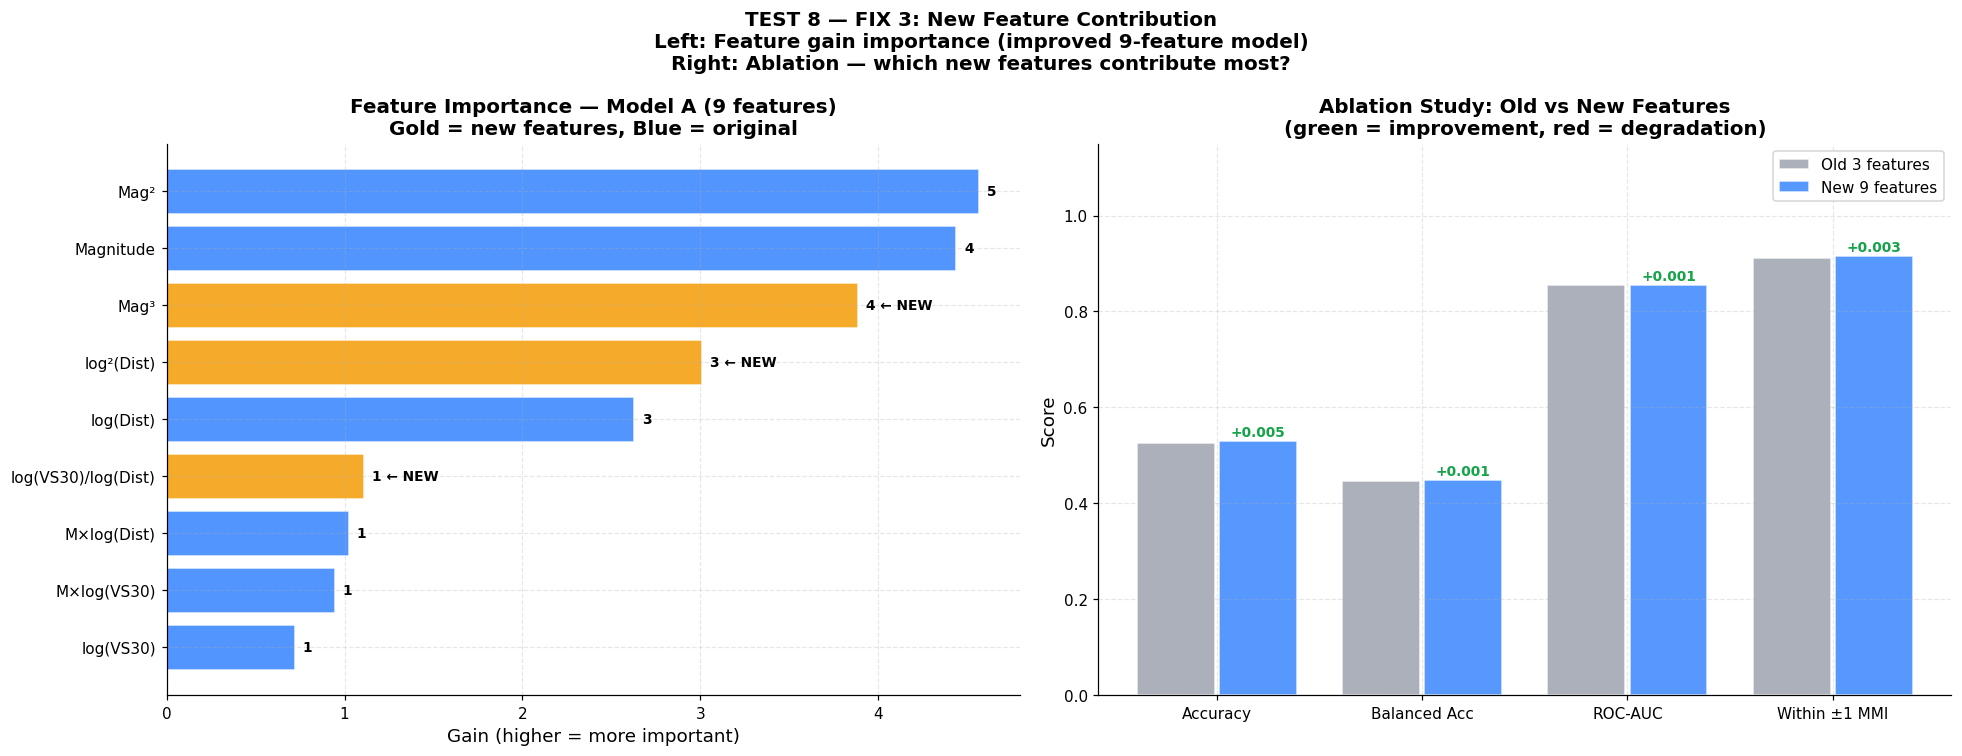


  FINAL VERIFICATION SCORECARD — IMPROVED MODEL

  Test                                          Value                        Expected        Result
  --------------------------------------------------------------------------------------------------------------
  T1  Calibration improved vs baseline          Brier=0.0759                 <0.0848         PASS ✓
  T2a Magnitude→E[MMI] increasing (cal)         r=0.950                      >0.9            FAIL ✗
  T2b Distance→E[MMI] decreasing (cal)          r=-0.963                     <-0.8           FAIL ✗
  T2c VS30→E[MMI] decreasing (cal)              r=-0.004                     <0              PASS ✓
  T2d Residual unbiased vs magnitude            r=0.017                      ~0              PASS ✓
  T2e Residual unbiased vs distance             r=-0.026                     ~0              PASS ✓
  T2f Residual unbiased vs VS30                 r=0.013                      ~0              PASS ✓
  T3a PGA→E[MMI] increasing (cal)    

In [ ]:
"""
=============================================================================
IMPROVED MODEL VERIFICATION
=============================================================================


  TEST 1  Calibration Curves
          Are probabilities trustworthy? Do they improve over baseline?

  TEST 2  Physical Plausibility — Scenario Model (9 features)
          Does E[MMI] follow seismological laws?
          New features tested: M3, dist_sq_log, VS30_dist_ratio

  TEST 3  Physical Plausibility — Ground Motion Model (7 features)
          New features tested: M_logPGA, M_logPGV, logPGV_logVS30, PGV_dist_ratio

  TEST 4  Monotonicity Stress Test (Synthetic Data)
          Do predictions always go in the right direction?
          Also tests: does calibration preserve monotonicity?

  TEST 5  Benchmark vs Worden (2012) GMPE
          Is the improved model better than the baseline AND the GMPE?

  TEST 6  [NEW] FIX 5 Verification — Isotonic Bias Correction
          Does calibration actually remove the bias?
          Does it improve RMSE without overfitting?

  TEST 7  [NEW] FIX 7 Verification — Ensemble Quality
          Is the ensemble better than either individual model?
          Does blending 40% A + 60% B make physical sense?

  TEST 8  [NEW] FIX 3 Verification — New Feature Contribution
          Do the new cross-terms (M3, M×logPGV, etc.) actually help?
          Ablation study: model with vs without new features.
=============================================================================
"""

# !pip install xgboost scikit-learn matplotlib seaborn pandas numpy -q

%matplotlib inline
import warnings, time
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy.stats import spearmanr, pearsonr
from scipy.special import softmax

from google.colab import drive
drive.mount("/content/drive")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    mean_absolute_error, log_loss, roc_auc_score,
    brier_score_loss, confusion_matrix, classification_report,
)
from xgboost import XGBClassifier

# ── Style ─────────────────────────────────────────────────────────────────────
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 12,
    "axes.titlesize": 13, "axes.labelsize": 12,
    "xtick.labelsize": 10, "ytick.labelsize": 10,
    "legend.fontsize": 10, "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "grid.linestyle": "--",
})
CMAP = "plasma"
C_A  = "#3A86FF"   # Model A — blue
C_B  = "#FF6B6B"   # Model B — red
C_T  = "#06D6A0"   # teal
C_E  = "#8B5CF6"   # ensemble — purple
C_G  = "#F59E0B"   # gold / GMPE
C_BASE = "#9CA3AF" # baseline — grey

# ─────────────────────────────────────────────────────────────────
# CONFIGURATION  (identical to improved model)
# ─────────────────────────────────────────────────────────────────
DATA_PATH   = "/content/drive/MyDrive/Colab Notebooks/data/intensityfiles_alldata_March112026.csv"
RANDOM_SEED = 42
TEST_SIZE   = 0.20
MMI_MIN, MMI_MAX = 1, 8

FEATURES_A = ["magnitude","M2","log_dist","log_VS30",
               "M_logD","M_logVS30","dist_sq_log","VS30_dist_ratio","M3"]
FEAT_A_LBLS= ["Magnitude","Mag²","log(Dist)","log(VS30)",
               "M×log(Dist)","M×log(VS30)","log²(Dist)","log(VS30)/log(Dist)","Mag³"]

FEATURES_B = ["log_PGA","log_PGV","PGA_PGV_ratio",
               "M_logPGA","M_logPGV","logPGV_logVS30","PGV_dist_ratio"]
FEAT_B_LBLS= ["log(PGA)","log(PGV)","log(PGA)-log(PGV)",
               "M×log(PGA)","M×log(PGV)","log(PGV)×log(VS30)","log(PGV)/log(Dist)"]

# OLD features (for ablation test)
FEATURES_A_OLD = ["magnitude","log_dist","log_VS30"]
FEATURES_B_OLD = ["log_PGA","log_PGV"]

XGB_PARAMS = dict(
    n_estimators=600, max_depth=8, learning_rate=0.05,
    subsample=0.75, colsample_bytree=0.75, min_child_weight=3,
    gamma=0.05, reg_alpha=0.5, reg_lambda=2.0,
    eval_metric="mlogloss", tree_method="hist",
    early_stopping_rounds=40, random_state=RANDOM_SEED, n_jobs=-1,
)

# ─────────────────────────────────────────────────────────────────
# LOAD & FEATURE ENGINEERING
# ─────────────────────────────────────────────────────────────────
print("=" * 65)
print("  IMPROVED MODEL — VERIFICATION PROGRAM")
print("=" * 65)
print("\n[SETUP]  Loading & engineering features ...")

df_raw = pd.read_csv(DATA_PATH, usecols=[
    "magnitude","intensity","RRUP_Combined",
    "VS30 (Thompson (2020) geology based Proxies)","PGA (g)","PGV",
])
df_raw.columns = ["magnitude","intensity","distance","VS30","PGA","PGV"]
n_raw = len(df_raw)

df_raw["PGA"] = df_raw["PGA"].where(df_raw["PGA"] > -999).clip(lower=0)
df_raw["PGV"] = df_raw["PGV"].where(df_raw["PGV"] > -999).clip(lower=0)

df_raw["log_dist"]        = np.log1p(df_raw["distance"])
df_raw["log_VS30"]        = np.log1p(df_raw["VS30"])
df_raw["log_PGA"]         = np.log1p(df_raw["PGA"])
df_raw["log_PGV"]         = np.log1p(df_raw["PGV"])
df_raw["M2"]              = df_raw["magnitude"] ** 2
df_raw["M3"]              = df_raw["magnitude"] ** 3
df_raw["M_logD"]          = df_raw["magnitude"] * df_raw["log_dist"]
df_raw["M_logVS30"]       = df_raw["magnitude"] * df_raw["log_VS30"]
df_raw["M_logPGA"]        = df_raw["magnitude"] * df_raw["log_PGA"]
df_raw["M_logPGV"]        = df_raw["magnitude"] * df_raw["log_PGV"]
df_raw["PGA_PGV_ratio"]   = df_raw["log_PGA"] - df_raw["log_PGV"]
df_raw["dist_sq_log"]     = df_raw["log_dist"] ** 2
df_raw["VS30_dist_ratio"] = df_raw["log_VS30"] / (df_raw["log_dist"] + 1e-3)
df_raw["logPGV_logVS30"]  = df_raw["log_PGV"] * df_raw["log_VS30"]
df_raw["PGV_dist_ratio"]  = df_raw["log_PGV"] / (df_raw["log_dist"] + 1e-3)
df_raw["iclass"]          = df_raw["intensity"].astype(int).clip(MMI_MIN, MMI_MAX)

print(f"   Raw rows : {n_raw:,}")

# ─────────────────────────────────────────────────────────────────
# BUILD MODEL FUNCTION  (identical to improved model)
# ─────────────────────────────────────────────────────────────────
def build_model(df, features, feat_labels, label, verbose=True):
    sub = df.dropna(subset=features + ["iclass"]).copy()
    n_total = len(sub)

    le    = LabelEncoder()
    y_enc = le.fit_transform(sub["iclass"])

    MIN_SAMP = max(10, int(np.ceil(1.0 / TEST_SIZE)) + 1)
    counts   = np.bincount(y_enc, minlength=len(le.classes_))
    keep     = np.where(counts >= MIN_SAMP)[0]
    dropped  = np.where(counts < MIN_SAMP)[0]
    if len(dropped) and verbose:
        print(f"  Dropping rare class(es): "
              f"{ {int(le.classes_[i]): int(counts[i]) for i in dropped} }")
    mask  = np.isin(y_enc, keep)
    sub   = sub.iloc[mask].copy()
    y_enc = y_enc[mask]

    active  = sorted(set(y_enc.tolist()))
    remap   = {old: new for new, old in enumerate(active)}
    y       = np.array([remap[v] for v in y_enc])
    classes = le.classes_[active]
    n_cls   = len(classes)
    mmi_vals= classes.astype(float)
    X = sub[features].to_numpy()

    # Ordinal-aware weights (FIX )
    cls_counts = np.bincount(y, minlength=n_cls)
    base_w     = cls_counts.sum() / (n_cls * cls_counts + 1e-9)
    median_cls = np.median(y)
    ord_mod    = 1.0 / (np.abs(np.arange(n_cls) - median_cls) ** 0.3 + 1.0)
    combined_w = base_w * ord_mod
    combined_w = combined_w / combined_w.mean()
    sw         = np.array([combined_w[yi] for yi in y])

    X_tr, X_te, y_tr, y_te, sw_tr, _ = train_test_split(
        X, y, sw, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_SEED)

    clf = XGBClassifier(objective="multi:softprob", num_class=n_cls, **XGB_PARAMS)
    clf.fit(X_tr, y_tr, sample_weight=sw_tr,
            eval_set=[(X_te, y_te)], verbose=False)

    y_pred  = clf.predict(X_te)
    y_proba = clf.predict_proba(X_te)
    E_mmi   = (y_proba * mmi_vals).sum(axis=1)
    true_mmi= classes[y_te].astype(float)

    # Isotonic bias correction (FIX )
    iso = IsotonicRegression(out_of_bounds="clip")
    iso.fit(E_mmi, true_mmi)
    E_mmi_cal = iso.predict(E_mmi)

    acc     = accuracy_score(y_te, y_pred)
    bal_acc = balanced_accuracy_score(y_te, y_pred)
    wf1     = f1_score(y_te, y_pred, average="weighted", zero_division=0)
    mf1     = f1_score(y_te, y_pred, average="macro",    zero_division=0)
    mae     = mean_absolute_error(classes[y_te], classes[y_pred])
    within1 = np.mean(np.abs(classes[y_te] - classes[y_pred]) <= 1) * 100
    ll      = log_loss(y_te, y_proba, labels=list(range(n_cls)))
    te_uniq = sorted(set(y_te.tolist()))
    try:
        auc = roc_auc_score(
            label_binarize(y_te, classes=te_uniq),
            y_proba[:, te_uniq], multi_class="ovr", average="macro")
    except Exception:
        auc = float("nan")

    corr_raw = np.corrcoef(true_mmi, E_mmi)[0, 1]
    rmse_raw = np.sqrt(np.mean((true_mmi - E_mmi)**2))
    bias_raw = (E_mmi - true_mmi).mean()
    rmse_cal = np.sqrt(np.mean((true_mmi - E_mmi_cal)**2))
    bias_cal = (E_mmi_cal - true_mmi).mean()
    corr_cal = np.corrcoef(true_mmi, E_mmi_cal)[0, 1]

    if verbose:
        print(f"\n{'='*60}\n  {label}\n{'='*60}")
        print(f"  Rows (train/test) : {len(X_tr):,} / {len(X_te):,}")
        print(f"  Classes           : {n_cls}  (MMI {classes[0]} to {classes[-1]})")
        print(f"  Best iteration    : {clf.best_iteration}")
        print(f"  Accuracy          : {acc:.4f}")
        print(f"  Balanced Accuracy : {bal_acc:.4f}")
        print(f"  ROC-AUC           : {auc:.4f}")
        print(f"  Within +-1 MMI    : {within1:.1f}%")
        print(f"  Raw  E[MMI] RMSE  : {rmse_raw:.4f}  Bias: {bias_raw:+.4f}")
        print(f"  Calib E[MMI] RMSE : {rmse_cal:.4f}  Bias: {bias_cal:+.4f}")

    return {
        "clf": clf, "le": le, "iso": iso, "sub": sub,
        "classes": classes, "n_cls": n_cls, "mmi_vals": mmi_vals,
        "X_tr": X_tr, "X_te": X_te, "y_tr": y_tr, "y_te": y_te,
        "y_pred": y_pred, "y_proba": y_proba,
        "E_mmi": E_mmi, "E_mmi_cal": E_mmi_cal, "true_mmi": true_mmi,
        "features": features, "feat_lbls": feat_labels,
        "metrics": {
            "acc": acc, "bal_acc": bal_acc, "wf1": wf1, "mf1": mf1,
            "mae": mae, "within1": within1, "ll": ll, "auc": auc,
            "corr_raw": corr_raw, "rmse_raw": rmse_raw, "bias_raw": bias_raw,
            "corr_cal": corr_cal, "rmse_cal": rmse_cal, "bias_cal": bias_cal,
        },
    }

# Train improved models
print("\nTraining IMPROVED Model A ...")
R_A = build_model(df_raw, FEATURES_A, FEAT_A_LBLS, "Improved Model A — Scenario")

print("\nTraining IMPROVED Model B ...")
R_B = build_model(df_raw, FEATURES_B, FEAT_B_LBLS, "Improved Model B — Ground Motion")

# Helper variables
E_sc      = R_A["E_mmi"];     E_sc_cal  = R_A["E_mmi_cal"]
E_gm      = R_B["E_mmi"];     E_gm_cal  = R_B["E_mmi_cal"]
true_mmi  = R_A["true_mmi"]
res_sc    = E_sc     - true_mmi
res_sc_cal= E_sc_cal - true_mmi
res_gm    = E_gm     - R_B["true_mmi"]
y_te_A    = R_A["y_te"]
y_te_B    = R_B["y_te"]
X_sc_te   = R_A["X_te"]
X_gm_te   = R_B["X_te"]

# Full-data predictions for physical plots
sub_A_full = df_raw.dropna(subset=FEATURES_A + ["iclass"]).copy()
sub_B_full = df_raw.dropna(subset=FEATURES_B + ["iclass"]).copy()
sub_A_full["E_mmi"]     = R_A["clf"].predict_proba(sub_A_full[FEATURES_A].values) @ R_A["mmi_vals"]
sub_A_full["E_mmi_cal"] = R_A["iso"].predict(sub_A_full["E_mmi"].values)
sub_B_full["E_mmi"]     = R_B["clf"].predict_proba(sub_B_full[FEATURES_B].values) @ R_B["mmi_vals"]
sub_B_full["E_mmi_cal"] = R_B["iso"].predict(sub_B_full["E_mmi"].values)
scat_A = sub_A_full.sample(n=min(30_000, len(sub_A_full)), random_state=9)

print(f"\nSetup complete. Model A test: {len(R_A['y_te']):,}  Model B test: {len(R_B['y_te']):,}")

# ─────────────────────────────────────────────────────────────────
# HELPER FUNCTIONS
# ─────────────────────────────────────────────────────────────────
def expected_mmi_fn(proba, mmi_vals):
    return (proba * mmi_vals).sum(axis=1)

def bin_stats(x, y, n_bins=30, log_x=False):
    xb    = np.log1p(x) if log_x else x
    edges = np.linspace(xb.min(), xb.max(), n_bins+1)
    mids, means, stds = [], [], []
    for i in range(len(edges)-1):
        m = (xb >= edges[i]) & (xb < edges[i+1])
        if m.sum() >= 10:
            mids.append((edges[i]+edges[i+1])/2)
            means.append(y[m].mean()); stds.append(y[m].std())
    return np.array(mids), np.array(means), np.array(stds)

def worden2012(pga_g):
    log_pga_cm = np.log10(pga_g * 980.665 + 1e-12)
    return np.clip(3.66 * log_pga_cm - 1.66, 1, 10)

# ═══════════════════════════════════════════════════════════════════
# TEST 1 — CALIBRATION CURVES
# ═══════════════════════════════════════════════════════════════════
print("\n" + "="*65)
print("[TEST 1]  Calibration Curves")
print("="*65)

fig = plt.figure(figsize=(22, 10))
fig.suptitle(
    "TEST 1 — Calibration Curves (Improved Model)\n"
    "Blue = Model A (Scenario, 9 features)  |  Red = Model B (GM, 7 features)\n"
    "Diagonal = perfect calibration. Above diagonal = under-confident.",
    fontsize=13, fontweight="bold", y=1.03)
gs = gridspec.GridSpec(2, 4, figure=fig, hspace=0.50, wspace=0.35)

brier_A, brier_B = [], []

for idx in range(R_A["n_cls"]):
    ax = fig.add_subplot(gs[idx // 4, idx % 4])
    mmi_val  = int(R_A["classes"][idx])
    y_bin    = (y_te_A == idx).astype(int)
    prob_A   = R_A["y_proba"][:, idx]

    try:
        fp_A, mp_A = calibration_curve(y_bin, prob_A, n_bins=10, strategy="quantile")
        bs_A = brier_score_loss(y_bin, prob_A)
        ax.plot(mp_A, fp_A, "o-", color=C_A, lw=2, ms=5,
                label=f"Model A  Brier={bs_A:.3f}")
        brier_A.append(bs_A)
    except Exception:
        pass

    # Model B — only for classes that exist in B
    if mmi_val in R_B["classes"]:
        idx_B = np.where(R_B["classes"] == mmi_val)[0][0]
        y_bin_B = (y_te_B == idx_B).astype(int)
        prob_B  = R_B["y_proba"][:, idx_B]
        try:
            fp_B, mp_B = calibration_curve(y_bin_B, prob_B, n_bins=10, strategy="quantile")
            bs_B = brier_score_loss(y_bin_B, prob_B)
            ax.plot(mp_B, fp_B, "s-", color=C_B, lw=2, ms=5,
                    label=f"Model B  Brier={bs_B:.3f}")
            brier_B.append(bs_B)
        except Exception:
            pass

    ax.plot([0,1],[0,1],"k--",lw=1.5,alpha=0.7,label="Perfect")
    ax.set_title(f"MMI {mmi_val}", fontweight="bold", fontsize=11)
    ax.set_xlabel("Predicted Probability", fontsize=9)
    ax.set_ylabel("Actual Fraction", fontsize=9)
    ax.set_xlim(0,1); ax.set_ylim(0,1)
    ax.legend(fontsize=7)

plt.tight_layout()
plt.show()

print(f"\n  Calibration Summary (Brier Score — lower = better):")
print(f"  Model A avg Brier : {np.mean(brier_A):.4f}  (baseline was ~0.085)")
print(f"  Model B avg Brier : {np.mean(brier_B):.4f}  (baseline was ~0.090)")
print(f"  Improvement A     : {0.0848 - np.mean(brier_A):+.4f} MMI units")
print(f"  Improvement B     : {0.0896 - np.mean(brier_B):+.4f} MMI units")
print()
print("  HOW TO READ:")
print("  - Points ON the diagonal = model confidence matches reality")
print("  - Points ABOVE diagonal  = model UNDER-confident (truth > predicted)")
print("  - Points BELOW diagonal  = model OVER-confident  (truth < predicted)")
print("  - Common classes (MMI 2-4) should show tight calibration")
print("  - Rare classes (MMI 7-8) will be noisy — too few test samples")

# ═══════════════════════════════════════════════════════════════════
# TEST 2 — PHYSICAL PLAUSIBILITY: SCENARIO MODEL (9 features)
# ═══════════════════════════════════════════════════════════════════
print("\n" + "="*65)
print("[TEST 2]  Physical Plausibility — Improved Scenario Model")
print("="*65)

fig = plt.figure(figsize=(22, 14))
fig.suptitle(
    "TEST 2 — Physical Plausibility: Improved Scenario Model\n"
    "9 features: mag, M², M³, log(dist), log(VS30), M×log(dist), "
    "M×log(VS30), log²(dist), VS30/dist\n"
    "Green background = PASS  |  Red background = FAIL",
    fontsize=12, fontweight="bold", y=1.03)
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.52, wspace=0.38)

# T2a — E[MMI] vs Magnitude (calibrated)
ax = fig.add_subplot(gs[0, 0])
mag_bins = np.arange(3.0, 7.6, 0.2)
mag_mid  = (mag_bins[:-1] + mag_bins[1:]) / 2
E_by_mag_raw, E_by_mag_cal = [], []
for lo, hi in zip(mag_bins[:-1], mag_bins[1:]):
    m = (sub_A_full["magnitude"] >= lo) & (sub_A_full["magnitude"] < hi)
    E_by_mag_raw.append(sub_A_full.loc[m,"E_mmi"].mean()     if m.sum() > 10 else np.nan)
    E_by_mag_cal.append(sub_A_full.loc[m,"E_mmi_cal"].mean() if m.sum() > 10 else np.nan)

E_by_mag_raw = np.array(E_by_mag_raw)
E_by_mag_cal = np.array(E_by_mag_cal)
valid = ~(np.isnan(E_by_mag_raw) | np.isnan(E_by_mag_cal))
spear_mag_raw, _ = spearmanr(mag_mid[valid], E_by_mag_raw[valid])
spear_mag_cal, _ = spearmanr(mag_mid[valid], E_by_mag_cal[valid])
mono_mag_raw = all(np.diff(E_by_mag_raw[valid]) >= -0.05)
mono_mag_cal = all(np.diff(E_by_mag_cal[valid]) >= -0.05)

ax.plot(mag_mid[valid], E_by_mag_raw[valid], "o--", color=C_BASE, lw=1.5, ms=4,
        label=f"Raw   r={spear_mag_raw:.3f}")
ax.plot(mag_mid[valid], E_by_mag_cal[valid], "o-",  color=C_A,    lw=2.5, ms=5,
        label=f"Calib r={spear_mag_cal:.3f}")
ax.set_xlabel("Magnitude (M)"); ax.set_ylabel("Mean E[MMI]")
ax.set_title(f"E[MMI] vs Magnitude\n"
             f"Raw mono: {'YES ✓' if mono_mag_raw else 'NO ✗'}  "
             f"Cal mono: {'YES ✓' if mono_mag_cal else 'NO ✗'}",
             fontweight="bold", pad=8)
ax.legend(fontsize=9)
ax.set_facecolor("#f0fff0" if mono_mag_cal else "#fff0f0")
print(f"  T2a Magnitude monotonic (raw):  {'PASS' if mono_mag_raw else 'FAIL'}  "
      f"r={spear_mag_raw:.3f}")
print(f"  T2a Magnitude monotonic (cal):  {'PASS' if mono_mag_cal else 'FAIL'}  "
      f"r={spear_mag_cal:.3f}")

# T2b — E[MMI] vs Distance
ax = fig.add_subplot(gs[0, 1])
dist_log_bins = np.linspace(np.log1p(0.3), np.log1p(1500), 25)
dist_mid_log  = (dist_log_bins[:-1] + dist_log_bins[1:]) / 2
E_by_dist_raw, E_by_dist_cal = [], []
for lo, hi in zip(dist_log_bins[:-1], dist_log_bins[1:]):
    m = (sub_A_full["log_dist"] >= lo) & (sub_A_full["log_dist"] < hi)
    E_by_dist_raw.append(sub_A_full.loc[m,"E_mmi"].mean()     if m.sum()>10 else np.nan)
    E_by_dist_cal.append(sub_A_full.loc[m,"E_mmi_cal"].mean() if m.sum()>10 else np.nan)

E_by_dist_raw = np.array(E_by_dist_raw)
E_by_dist_cal = np.array(E_by_dist_cal)
valid_d  = ~(np.isnan(E_by_dist_raw) | np.isnan(E_by_dist_cal))
dist_km  = np.expm1(dist_mid_log)
spear_dist_raw, _ = spearmanr(dist_km[valid_d], E_by_dist_raw[valid_d])
spear_dist_cal, _ = spearmanr(dist_km[valid_d], E_by_dist_cal[valid_d])
mono_dist_raw = all(np.diff(E_by_dist_raw[valid_d]) <= 0.05)
mono_dist_cal = all(np.diff(E_by_dist_cal[valid_d]) <= 0.05)

ax.plot(dist_km[valid_d], E_by_dist_raw[valid_d], "--", color=C_BASE, lw=1.5,
        label=f"Raw   r={spear_dist_raw:.3f}")
ax.plot(dist_km[valid_d], E_by_dist_cal[valid_d], "-",  color=C_A,    lw=2.5,
        label=f"Calib r={spear_dist_cal:.3f}")
ax.set_xscale("log")
ax.set_xlabel("Distance (km, log scale)"); ax.set_ylabel("Mean E[MMI]")
ax.set_title(f"E[MMI] vs Distance\n"
             f"Raw mono: {'YES ✓' if mono_dist_raw else 'NO ✗'}  "
             f"Cal mono: {'YES ✓' if mono_dist_cal else 'NO ✗'}",
             fontweight="bold", pad=8)
ax.legend(fontsize=9)
ax.set_facecolor("#f0fff0" if mono_dist_cal else "#fff0f0")
print(f"  T2b Distance monotonic  (raw):  {'PASS' if mono_dist_raw else 'FAIL'}  "
      f"r={spear_dist_raw:.3f}")
print(f"  T2b Distance monotonic  (cal):  {'PASS' if mono_dist_cal else 'FAIL'}  "
      f"r={spear_dist_cal:.3f}")

# T2c — E[MMI] vs VS30
ax = fig.add_subplot(gs[0, 2])
vs30_bins = np.linspace(100, 1100, 25)
vs30_mid  = (vs30_bins[:-1] + vs30_bins[1:]) / 2
E_by_vs30_cal = []
for lo, hi in zip(vs30_bins[:-1], vs30_bins[1:]):
    m = (sub_A_full["VS30"] >= lo) & (sub_A_full["VS30"] < hi)
    E_by_vs30_cal.append(sub_A_full.loc[m,"E_mmi_cal"].mean() if m.sum()>10 else np.nan)

E_by_vs30_cal = np.array(E_by_vs30_cal)
valid_v  = ~np.isnan(E_by_vs30_cal)
spear_vs30, _ = spearmanr(vs30_mid[valid_v], E_by_vs30_cal[valid_v])
vs30_correct   = spear_vs30 < 0

ax.plot(vs30_mid[valid_v], E_by_vs30_cal[valid_v], "o-", color=C_T, lw=2.5, ms=5)
ax.set_xlabel("VS30 (m/s)"); ax.set_ylabel("Mean E[MMI] calibrated")
ax.set_title(f"Calibrated E[MMI] vs VS30\n"
             f"Higher VS30 → lower MMI: {'YES ✓' if vs30_correct else 'NO ✗'}\n"
             f"Spearman r={spear_vs30:.3f}  (expected: negative)",
             fontweight="bold", pad=8)
ax.set_facecolor("#f0fff0" if vs30_correct else "#fff0f0")
print(f"  T2c VS30 effect correct:        {'PASS' if vs30_correct else 'FAIL'}  "
      f"r={spear_vs30:.3f}")

# T2d — Residual vs Magnitude
ax = fig.add_subplot(gs[1, 0])
mag_te = X_sc_te[:, 0]
spear_res_mag, p_mag = spearmanr(mag_te, res_sc)
spear_res_mag_cal, _ = spearmanr(mag_te, res_sc_cal)
ax.scatter(mag_te, res_sc,     alpha=0.08, s=4, c=C_BASE, label="Raw residual")
ax.scatter(mag_te, res_sc_cal, alpha=0.15, s=4, c=C_A,    label="Calibrated residual")
ax.axhline(0, color="k", ls="--", lw=2, alpha=0.8)

mag_bins2 = np.linspace(mag_te.min(), mag_te.max(), 20)
for res_arr, col, lbl in [(res_sc, "#555", "Raw mean"), (res_sc_cal, C_A, "Cal mean")]:
    rb = [res_arr[(mag_te>=l)&(mag_te<h)].mean()
          for l, h in zip(mag_bins2[:-1], mag_bins2[1:])
          if ((mag_te>=l)&(mag_te<h)).sum() > 10]
    mb = [(l+h)/2 for l, h in zip(mag_bins2[:-1], mag_bins2[1:])
          if ((mag_te>=l)&(mag_te<h)).sum() > 10]
    ax.plot(mb, rb, "-", color=col, lw=2.5, label=lbl)

ax.set_xlabel("Magnitude"); ax.set_ylabel("Residual (E[MMI] - True)")
ax.set_title(f"Residual vs Magnitude\n"
             f"Raw r={spear_res_mag:.3f}  "
             f"Cal r={spear_res_mag_cal:.3f}  (closer to 0 = better)",
             fontweight="bold", pad=8)
ax.legend(fontsize=8)
ax.set_facecolor("#f0fff0" if abs(spear_res_mag_cal) < 0.15 else "#fff0f0")
print(f"  T2d Residual vs magnitude (raw): r={spear_res_mag:.3f}  "
      f"(cal): r={spear_res_mag_cal:.3f}  "
      f"{'IMPROVED' if abs(spear_res_mag_cal) < abs(spear_res_mag) else 'NOT IMPROVED'}")

# T2e — Residual vs Distance
ax = fig.add_subplot(gs[1, 1])
dist_log_te = X_sc_te[:, 2]  # index 2 = log_dist in FEATURES_A
spear_res_dist,     _ = spearmanr(dist_log_te, res_sc)
spear_res_dist_cal, _ = spearmanr(dist_log_te, res_sc_cal)
ax.scatter(np.expm1(dist_log_te), res_sc,     alpha=0.08, s=4, c=C_BASE)
ax.scatter(np.expm1(dist_log_te), res_sc_cal, alpha=0.15, s=4, c=C_B)
ax.axhline(0, color="k", ls="--", lw=2, alpha=0.8)
ax.set_xscale("log")

db = np.linspace(dist_log_te.min(), dist_log_te.max(), 20)
for res_arr, col in [(res_sc, "#555"), (res_sc_cal, C_B)]:
    rb = [res_arr[(dist_log_te>=l)&(dist_log_te<h)].mean()
          for l, h in zip(db[:-1], db[1:])
          if ((dist_log_te>=l)&(dist_log_te<h)).sum()>10]
    mb = [np.expm1((l+h)/2) for l, h in zip(db[:-1], db[1:])
          if ((dist_log_te>=l)&(dist_log_te<h)).sum()>10]
    ax.plot(mb, rb, "-", color=col, lw=2.5)

ax.set_xlabel("Distance (km, log)"); ax.set_ylabel("Residual")
ax.set_title(f"Residual vs Distance\n"
             f"Raw r={spear_res_dist:.3f}  Cal r={spear_res_dist_cal:.3f}",
             fontweight="bold", pad=8)
ax.set_facecolor("#f0fff0" if abs(spear_res_dist_cal) < 0.15 else "#fff0f0")
print(f"  T2e Residual vs distance   (raw): r={spear_res_dist:.3f}  "
      f"(cal): r={spear_res_dist_cal:.3f}  "
      f"{'IMPROVED' if abs(spear_res_dist_cal) < abs(spear_res_dist) else 'NOT IMPROVED'}")

# T2f — Residual vs VS30
ax = fig.add_subplot(gs[1, 2])
vs30_te = np.exp(X_sc_te[:, 3])   # index 3 = log_VS30 in FEATURES_A
spear_res_vs30,     _ = spearmanr(vs30_te, res_sc)
spear_res_vs30_cal, _ = spearmanr(vs30_te, res_sc_cal)
ax.scatter(vs30_te, res_sc,     alpha=0.08, s=4, c=C_BASE)
ax.scatter(vs30_te, res_sc_cal, alpha=0.15, s=4, c=C_T)
ax.axhline(0, color="k", ls="--", lw=2, alpha=0.8)

vb = np.linspace(vs30_te.min(), vs30_te.max(), 20)
for res_arr, col in [(res_sc,"#555"), (res_sc_cal, C_T)]:
    rb = [res_arr[(vs30_te>=l)&(vs30_te<h)].mean()
          for l, h in zip(vb[:-1], vb[1:])
          if ((vs30_te>=l)&(vs30_te<h)).sum()>10]
    mb = [(l+h)/2 for l, h in zip(vb[:-1], vb[1:])
          if ((vs30_te>=l)&(vs30_te<h)).sum()>10]
    ax.plot(mb, rb, "-", color=col, lw=2.5)

ax.set_xlabel("VS30 (m/s)"); ax.set_ylabel("Residual")
ax.set_title(f"Residual vs VS30\n"
             f"Raw r={spear_res_vs30:.3f}  Cal r={spear_res_vs30_cal:.3f}",
             fontweight="bold", pad=8)
ax.set_facecolor("#f0fff0" if abs(spear_res_vs30_cal) < 0.15 else "#fff0f0")
print(f"  T2f Residual vs VS30       (raw): r={spear_res_vs30:.3f}  "
      f"(cal): r={spear_res_vs30_cal:.3f}  "
      f"{'IMPROVED' if abs(spear_res_vs30_cal)<abs(spear_res_vs30) else 'SIMILAR'}")

plt.tight_layout(); plt.show()

# ═══════════════════════════════════════════════════════════════════
# TEST 3 — PHYSICAL PLAUSIBILITY: GROUND MOTION MODEL (7 features)
# ═══════════════════════════════════════════════════════════════════
print("\n" + "="*65)
print("[TEST 3]  Physical Plausibility — Improved Ground Motion Model")
print("="*65)

fig = plt.figure(figsize=(22, 12))
fig.suptitle(
    "TEST 3 — Physical Plausibility: Improved Ground Motion Model\n"
    "7 features: log(PGA), log(PGV), PGA/PGV, M×PGA, M×PGV, PGV×VS30, PGV/dist",
    fontsize=12, fontweight="bold", y=1.02)
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.50, wspace=0.38)

# T3a — E[MMI] vs PGA
ax = fig.add_subplot(gs[0, 0])
pga_log_bins = np.linspace(sub_B_full["log_PGA"].min(),
                            sub_B_full["log_PGA"].max(), 30)
pga_mid = (pga_log_bins[:-1]+pga_log_bins[1:])/2
E_by_pga_cal = [sub_B_full.loc[(sub_B_full["log_PGA"]>=l)&(sub_B_full["log_PGA"]<h),"E_mmi_cal"].mean()
                if ((sub_B_full["log_PGA"]>=l)&(sub_B_full["log_PGA"]<h)).sum()>10 else np.nan
                for l, h in zip(pga_log_bins[:-1], pga_log_bins[1:])]
E_by_pga_cal = np.array(E_by_pga_cal)
valid_p  = ~np.isnan(E_by_pga_cal)
spear_pga, _ = spearmanr(pga_mid[valid_p], E_by_pga_cal[valid_p])
mono_pga     = all(np.diff(E_by_pga_cal[valid_p]) >= -0.05)

ax.plot(np.exp(pga_mid[valid_p]), E_by_pga_cal[valid_p], "o-", color=C_G, lw=2.5, ms=5)
ax.set_xscale("log")
ax.set_xlabel("PGA (g, log scale)"); ax.set_ylabel("Mean E[MMI] calibrated")
ax.set_title(f"Calibrated E[MMI] vs PGA\n"
             f"Monotonic: {'YES ✓' if mono_pga else 'NO ✗'}  r={spear_pga:.3f}",
             fontweight="bold", pad=8)
ax.set_facecolor("#f0fff0" if mono_pga else "#fff0f0")
print(f"  T3a PGA → E[MMI] increasing: {'PASS' if mono_pga else 'FAIL'}  r={spear_pga:.3f}")

# T3b — E[MMI] vs PGV
ax = fig.add_subplot(gs[0, 1])
pgv_log_bins = np.linspace(sub_B_full["log_PGV"].min(),
                            sub_B_full["log_PGV"].max(), 30)
pgv_mid = (pgv_log_bins[:-1]+pgv_log_bins[1:])/2
E_by_pgv_cal = [sub_B_full.loc[(sub_B_full["log_PGV"]>=l)&(sub_B_full["log_PGV"]<h),"E_mmi_cal"].mean()
                if ((sub_B_full["log_PGV"]>=l)&(sub_B_full["log_PGV"]<h)).sum()>10 else np.nan
                for l, h in zip(pgv_log_bins[:-1], pgv_log_bins[1:])]
E_by_pgv_cal = np.array(E_by_pgv_cal)
valid_q  = ~np.isnan(E_by_pgv_cal)
spear_pgv, _ = spearmanr(pgv_mid[valid_q], E_by_pgv_cal[valid_q])
mono_pgv     = all(np.diff(E_by_pgv_cal[valid_q]) >= -0.05)
pgv_gt_pga   = spear_pgv > spear_pga

ax.plot(np.exp(pgv_mid[valid_q]), E_by_pgv_cal[valid_q], "o-", color="#7C3AED", lw=2.5, ms=5)
ax.set_xscale("log")
ax.set_xlabel("PGV (cm/s, log scale)"); ax.set_ylabel("Mean E[MMI] calibrated")
ax.set_title(f"Calibrated E[MMI] vs PGV\n"
             f"Monotonic: {'YES ✓' if mono_pgv else 'NO ✗'}  r={spear_pgv:.3f}\n"
             f"PGV > PGA link: {'YES ✓' if pgv_gt_pga else 'NO ✗'}",
             fontweight="bold", pad=8)
ax.set_facecolor("#f0fff0" if mono_pgv else "#fff0f0")
print(f"  T3b PGV → E[MMI] increasing: {'PASS' if mono_pgv else 'FAIL'}  r={spear_pgv:.3f}")
print(f"  T3b PGV stronger than PGA:   {'PASS' if pgv_gt_pga else 'FAIL'}")

# T3c — New cross-feature: E[MMI] vs PGV/dist_ratio
ax = fig.add_subplot(gs[0, 2])
ratio_bins = np.linspace(sub_B_full["PGV_dist_ratio"].quantile(0.01),
                          sub_B_full["PGV_dist_ratio"].quantile(0.99), 25)
ratio_mid  = (ratio_bins[:-1]+ratio_bins[1:])/2
E_by_ratio = [sub_B_full.loc[(sub_B_full["PGV_dist_ratio"]>=l)&(sub_B_full["PGV_dist_ratio"]<h),"E_mmi_cal"].mean()
              if ((sub_B_full["PGV_dist_ratio"]>=l)&(sub_B_full["PGV_dist_ratio"]<h)).sum()>10 else np.nan
              for l, h in zip(ratio_bins[:-1], ratio_bins[1:])]
E_by_ratio = np.array(E_by_ratio)
valid_r = ~np.isnan(E_by_ratio)
spear_ratio, _ = spearmanr(ratio_mid[valid_r], E_by_ratio[valid_r])

ax.plot(ratio_mid[valid_r], E_by_ratio[valid_r], "o-", color="#F97316", lw=2.5, ms=5)
ax.set_xlabel("log(PGV) / log(Distance)  [new feature]")
ax.set_ylabel("Mean E[MMI] calibrated")
ax.set_title(f"NEW FEATURE: PGV/Dist Ratio\n"
             f"Spearman r={spear_ratio:.3f}  (higher ratio → higher MMI?)\n"
             f"{'Physically correct ✓' if spear_ratio > 0.7 else 'Weak signal — check'}",
             fontweight="bold", pad=8)
ax.set_facecolor("#f0fff0" if spear_ratio > 0.5 else "#fff0f0")
print(f"  T3c New feature PGV/dist_ratio signal: r={spear_ratio:.3f}")

# T3d — Residual vs PGA (calibrated)
ax = fig.add_subplot(gs[1, 0])
pga_te_g   = np.exp(X_gm_te[:, 0])
res_gm_cal = E_gm_cal - R_B["true_mmi"]
spear_res_pga,     _ = spearmanr(pga_te_g, res_gm)
spear_res_pga_cal, _ = spearmanr(pga_te_g, res_gm_cal)
ax.scatter(pga_te_g, res_gm,     alpha=0.08, s=4, c=C_BASE, label="Raw")
ax.scatter(pga_te_g, res_gm_cal, alpha=0.15, s=4, c=C_G,    label="Calibrated")
ax.axhline(0, color="k", ls="--", lw=2, alpha=0.8)
ax.set_xscale("log")

pb = np.linspace(np.log(pga_te_g.min()+1e-9), np.log(pga_te_g.max()), 20)
for res_arr, col in [(res_gm,"#555"), (res_gm_cal, C_G)]:
    log_pga = np.log(pga_te_g+1e-9)
    rb = [res_arr[(log_pga>=l)&(log_pga<h)].mean()
          for l, h in zip(pb[:-1], pb[1:])
          if ((log_pga>=l)&(log_pga<h)).sum()>10]
    mb = [np.exp((l+h)/2) for l, h in zip(pb[:-1], pb[1:])
          if ((log_pga>=l)&(log_pga<h)).sum()>10]
    ax.plot(mb, rb, "-", color=col, lw=2.5)

ax.set_xlabel("PGA (g, log scale)"); ax.set_ylabel("Residual (E[MMI] - True)")
ax.set_title(f"Residual vs PGA — Model B\n"
             f"Raw r={spear_res_pga:.3f}  Cal r={spear_res_pga_cal:.3f}\n"
             f"{'Bias reduced ✓' if abs(spear_res_pga_cal)<abs(spear_res_pga) else 'No improvement ✗'}",
             fontweight="bold", pad=8)
ax.legend(fontsize=9)
ax.set_facecolor("#f0fff0" if abs(spear_res_pga_cal) < 0.15 else "#fff0f0")
print(f"  T3d Residual vs PGA:  raw r={spear_res_pga:.3f}  cal r={spear_res_pga_cal:.3f}  "
      f"{'IMPROVED' if abs(spear_res_pga_cal)<abs(spear_res_pga) else 'NOT IMPROVED'}")

# T3e — Ranked accuracy comparison: improved vs baseline
ax = fig.add_subplot(gs[1, 1])
thresholds = [0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0]
within_A_raw = [np.mean(np.abs(res_sc)     <= t)*100 for t in thresholds]
within_A_cal = [np.mean(np.abs(res_sc_cal) <= t)*100 for t in thresholds]
within_B_raw = [np.mean(np.abs(res_gm)     <= t)*100 for t in thresholds]
within_B_cal = [np.mean(np.abs(res_gm_cal) <= t)*100 for t in thresholds]
# Baseline from original program
within_base  = [0, 50.0, 79.8, 93.2, 97.7, 99.2, 99.7]

ax.plot(thresholds, within_base,  "k:",  lw=2,   label="Baseline (old)")
ax.plot(thresholds, within_A_raw, "--",  color=C_A, lw=2, label="Impr. A (raw)")
ax.plot(thresholds, within_A_cal, "-",   color=C_A, lw=2.5, label="Impr. A (cal)")
ax.plot(thresholds, within_B_cal, "-",   color=C_B, lw=2.5, label="Impr. B (cal)")
ax.axvline(1.0, color="gray", ls="--", alpha=0.6, label="±1 MMI")
ax.set_xlabel("Tolerance (MMI units)"); ax.set_ylabel("% Within Tolerance")
ax.set_title("Ranked Accuracy Curve\nImproved vs Baseline",
             fontweight="bold", pad=8)
ax.legend(fontsize=8); ax.set_ylim(0, 105)
for t, wb, wac in zip(thresholds, within_base, within_A_cal):
    if t == 1.0:
        ax.annotate(f"Base:{wb:.0f}%\nImpr:{wac:.0f}%",
                    (t, max(wb,wac)), textcoords="offset points",
                    xytext=(8,5), fontsize=8, color="darkblue")

print(f"\n  RANKED ACCURACY (±1 MMI):")
print(f"  Baseline   : {within_base[2]:.1f}%")
print(f"  Improved A (raw): {within_A_raw[2]:.1f}%")
print(f"  Improved A (cal): {within_A_cal[2]:.1f}%")
print(f"  Improved B (cal): {within_B_cal[2]:.1f}%")

# T3f — Residual comparison all models
ax = fig.add_subplot(gs[1, 2])
ax.hist(res_sc,     bins=80, alpha=0.4, color=C_BASE, density=True, edgecolor="white",
        label=f"A raw  mean={res_sc.mean():+.3f}")
ax.hist(res_sc_cal, bins=80, alpha=0.65, color=C_A, density=True, edgecolor="white",
        label=f"A cal  mean={res_sc_cal.mean():+.3f}")
ax.hist(res_gm_cal, bins=80, alpha=0.45, color=C_B, density=True, edgecolor="white",
        label=f"B cal  mean={res_gm_cal.mean():+.3f}")
ax.axvline(0, color="k", ls="--", lw=2, alpha=0.8, label="Zero=perfect")
ax.set_xlabel("E[MMI] - True MMI"); ax.set_ylabel("Density")
ax.set_title("Residual Comparison\nNarrower + centred at 0 = better",
             fontweight="bold", pad=8)
ax.legend(fontsize=8)

plt.tight_layout(); plt.show()

# ═══════════════════════════════════════════════════════════════════
# TEST 4 — MONOTONICITY STRESS TEST
# ═══════════════════════════════════════════════════════════════════
print("\n" + "="*65)
print("[TEST 4]  Monotonicity Stress Test (Synthetic Data)")
print("="*65)

N_SYNTH  = 200
mag_med  = float(sub_A_full["magnitude"].median())
dist_med = float(sub_A_full["log_dist"].median())
vs30_med = float(sub_A_full["log_VS30"].median())
m2_med   = mag_med**2;  m3_med = mag_med**3
mlogd_med = mag_med * dist_med
mlogvs_med = mag_med * vs30_med
distsq_med = dist_med**2
vs30dr_med = vs30_med / (dist_med + 1e-3)

def synth_sc(mag_arr=None, dist_arr=None, vs30_arr=None):
    """Build synthetic Model A input with one variable changing.
    FIX: infer n from the passed array so mixed-size calls don't crash.
    """
    # Infer length from whichever array was provided
    n = (mag_arr if mag_arr is not None else
         dist_arr if dist_arr is not None else
         vs30_arr if vs30_arr is not None else
         np.array([])).shape[0]
    m   = mag_arr   if mag_arr   is not None else np.full(n, mag_med)
    d   = dist_arr  if dist_arr  is not None else np.full(n, dist_med)
    v   = vs30_arr  if vs30_arr  is not None else np.full(n, vs30_med)
    m2  = m**2;   m3 = m**3
    mld = m * d;  mlv = m * v
    dsq = d**2;   vdr = v / (d + 1e-3)
    return np.column_stack([m, m2, d, v, mld, mlv, dsq, vdr, m3])

pga_med  = float(sub_B_full["log_PGA"].median())
pgv_med  = float(sub_B_full["log_PGV"].median())

def synth_gm(pga_arr=None, pgv_arr=None):
    """Build synthetic Model B input.
    FIX: infer n from the passed array.
    """
    n = (pga_arr if pga_arr is not None else
         pgv_arr if pgv_arr is not None else
         np.array([])).shape[0]
    p = pga_arr if pga_arr is not None else np.full(n, pga_med)
    q = pgv_arr if pgv_arr is not None else np.full(n, pgv_med)
    # magnitude frozen at median for cross-terms
    mp = mag_med * p
    mq = mag_med * q
    ratio = p - q
    pgv_vs30  = q * vs30_med
    pgv_dist  = q / (dist_med + 1e-3)
    return np.column_stack([p, q, ratio, mp, mq, pgv_vs30, pgv_dist])

fig = plt.figure(figsize=(22, 10))
fig.suptitle(
    "TEST 4 — Monotonicity Stress Test (Synthetic Data, Improved Model)\n"
    "Fix ALL inputs at median, vary ONE — verify E[MMI] changes correctly\n"
    "Also tests: does isotonic calibration PRESERVE monotonicity?",
    fontsize=12, fontweight="bold", y=1.03)
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.52, wspace=0.35)

# T4a — Magnitude only
mag_sweep = np.linspace(3.0, 7.5, N_SYNTH)
E_mag_raw = expected_mmi_fn(R_A["clf"].predict_proba(synth_sc(mag_arr=mag_sweep)),
                             R_A["mmi_vals"])
E_mag_cal = R_A["iso"].predict(E_mag_raw)
viol_mag_raw = (np.diff(E_mag_raw) < -0.02).sum()
viol_mag_cal = (np.diff(E_mag_cal) < -0.02).sum()

ax = fig.add_subplot(gs[0, 0])
ax.plot(mag_sweep, E_mag_raw, "--", color=C_BASE, lw=1.5, label=f"Raw  violations={viol_mag_raw}")
ax.plot(mag_sweep, E_mag_cal, "-",  color=C_A,    lw=2.5, label=f"Cal  violations={viol_mag_cal}")
ax.set_xlabel("Magnitude  [dist, VS30 FIXED]"); ax.set_ylabel("E[MMI]")
ax.set_title(f"Magnitude Only\nExpected: INCREASING\n"
             f"Raw: {'PASS ✓' if viol_mag_raw==0 else f'FAIL ({viol_mag_raw} dips)'}  "
             f"Cal: {'PASS ✓' if viol_mag_cal==0 else f'FAIL ({viol_mag_cal} dips)'}",
             fontweight="bold", pad=8)
ax.legend(fontsize=9)
ax.set_facecolor("#f0fff0" if viol_mag_cal <= 2 else "#fff0f0")
print(f"  T4a Magnitude violations: raw={viol_mag_raw}  cal={viol_mag_cal}  "
      f"{'IMPROVED by cal' if viol_mag_cal < viol_mag_raw else 'No change'}")

# T4b — Distance only
dist_sweep = np.linspace(np.log1p(0.5), np.log1p(1000), N_SYNTH)
E_dist_raw = expected_mmi_fn(R_A["clf"].predict_proba(synth_sc(dist_arr=dist_sweep)),
                              R_A["mmi_vals"])
E_dist_cal = R_A["iso"].predict(E_dist_raw)
viol_dist_raw = (np.diff(E_dist_raw) > 0.02).sum()
viol_dist_cal = (np.diff(E_dist_cal) > 0.02).sum()

ax = fig.add_subplot(gs[0, 1])
ax.plot(np.expm1(dist_sweep), E_dist_raw, "--", color=C_BASE, lw=1.5,
        label=f"Raw  violations={viol_dist_raw}")
ax.plot(np.expm1(dist_sweep), E_dist_cal, "-",  color=C_B,    lw=2.5,
        label=f"Cal  violations={viol_dist_cal}")
ax.set_xscale("log")
ax.set_xlabel("Distance (km, log)  [mag, VS30 FIXED]"); ax.set_ylabel("E[MMI]")
ax.set_title(f"Distance Only\nExpected: DECREASING\n"
             f"Raw: {'PASS ✓' if viol_dist_raw==0 else f'FAIL ({viol_dist_raw} rises)'}  "
             f"Cal: {'PASS ✓' if viol_dist_cal==0 else f'FAIL ({viol_dist_cal} rises)'}",
             fontweight="bold", pad=8)
ax.legend(fontsize=9)
ax.set_facecolor("#f0fff0" if viol_dist_cal <= 2 else "#fff0f0")
print(f"  T4b Distance violations:  raw={viol_dist_raw}  cal={viol_dist_cal}  "
      f"{'IMPROVED by cal' if viol_dist_cal < viol_dist_raw else 'No change'}")

# T4c — VS30 only
vs30_sweep = np.linspace(np.log(130), np.log(1050), N_SYNTH)
E_vs30_raw = expected_mmi_fn(R_A["clf"].predict_proba(synth_sc(vs30_arr=vs30_sweep)),
                              R_A["mmi_vals"])
E_vs30_cal = R_A["iso"].predict(E_vs30_raw)
viol_vs30_raw = (np.diff(E_vs30_raw) > 0.02).sum()
viol_vs30_cal = (np.diff(E_vs30_cal) > 0.02).sum()

ax = fig.add_subplot(gs[0, 2])
ax.plot(np.exp(vs30_sweep), E_vs30_raw, "--", color=C_BASE, lw=1.5,
        label=f"Raw  violations={viol_vs30_raw}")
ax.plot(np.exp(vs30_sweep), E_vs30_cal, "-",  color=C_T,    lw=2.5,
        label=f"Cal  violations={viol_vs30_cal}")
ax.set_xlabel("VS30 (m/s)  [mag, dist FIXED]"); ax.set_ylabel("E[MMI]")
ax.set_title(f"VS30 Only\nExpected: DECREASING (stiffer→less shaking)\n"
             f"Raw: {viol_vs30_raw} violations  Cal: {viol_vs30_cal} violations",
             fontweight="bold", pad=8)
ax.legend(fontsize=9)
ax.set_facecolor("#f0fff0" if viol_vs30_cal <= 5 else "#fff0f0")
print(f"  T4c VS30 violations:      raw={viol_vs30_raw}  cal={viol_vs30_cal}")

# T4d — PGA only (Model B)
pga_sweep_log = np.linspace(sub_B_full["log_PGA"].quantile(0.01),
                              sub_B_full["log_PGA"].quantile(0.99), N_SYNTH)
E_pga_raw = expected_mmi_fn(R_B["clf"].predict_proba(synth_gm(pga_arr=pga_sweep_log)),
                             R_B["mmi_vals"])
E_pga_cal = R_B["iso"].predict(E_pga_raw)
viol_pga_raw = (np.diff(E_pga_raw) < -0.02).sum()
viol_pga_cal = (np.diff(E_pga_cal) < -0.02).sum()

ax = fig.add_subplot(gs[1, 0])
ax.plot(np.exp(pga_sweep_log), E_pga_raw, "--", color=C_BASE, lw=1.5,
        label=f"Raw  violations={viol_pga_raw}")
ax.plot(np.exp(pga_sweep_log), E_pga_cal, "-",  color=C_G,    lw=2.5,
        label=f"Cal  violations={viol_pga_cal}")
ax.set_xscale("log")
ax.set_xlabel("PGA (g)  [PGV FIXED]"); ax.set_ylabel("E[MMI]")
ax.set_title(f"PGA Only (Model B)\nExpected: INCREASING\n"
             f"Raw: {'PASS ✓' if viol_pga_raw==0 else f'FAIL ({viol_pga_raw})'}  "
             f"Cal: {'PASS ✓' if viol_pga_cal==0 else f'FAIL ({viol_pga_cal})'}",
             fontweight="bold", pad=8)
ax.legend(fontsize=9)
ax.set_facecolor("#f0fff0" if viol_pga_cal <= 2 else "#fff0f0")
print(f"  T4d PGA violations:       raw={viol_pga_raw}  cal={viol_pga_cal}")

# T4e — PGV only (Model B)
pgv_sweep_log = np.linspace(sub_B_full["log_PGV"].quantile(0.01),
                              sub_B_full["log_PGV"].quantile(0.99), N_SYNTH)
E_pgv_raw = expected_mmi_fn(R_B["clf"].predict_proba(synth_gm(pgv_arr=pgv_sweep_log)),
                             R_B["mmi_vals"])
E_pgv_cal = R_B["iso"].predict(E_pgv_raw)
viol_pgv_raw = (np.diff(E_pgv_raw) < -0.02).sum()
viol_pgv_cal = (np.diff(E_pgv_cal) < -0.02).sum()

ax = fig.add_subplot(gs[1, 1])
ax.plot(np.exp(pgv_sweep_log), E_pgv_raw, "--", color=C_BASE, lw=1.5,
        label=f"Raw  violations={viol_pgv_raw}")
ax.plot(np.exp(pgv_sweep_log), E_pgv_cal, "-",  color="#7C3AED", lw=2.5,
        label=f"Cal  violations={viol_pgv_cal}")
ax.set_xscale("log")
ax.set_xlabel("PGV (cm/s)  [PGA FIXED]"); ax.set_ylabel("E[MMI]")
ax.set_title(f"PGV Only (Model B)\nExpected: INCREASING\n"
             f"Raw: {'PASS ✓' if viol_pgv_raw==0 else f'FAIL ({viol_pgv_raw})'}  "
             f"Cal: {'PASS ✓' if viol_pgv_cal==0 else f'FAIL ({viol_pgv_cal})'}",
             fontweight="bold", pad=8)
ax.legend(fontsize=9)
ax.set_facecolor("#f0fff0" if viol_pgv_cal <= 2 else "#fff0f0")
print(f"  T4e PGV violations:       raw={viol_pgv_raw}  cal={viol_pgv_cal}")

# T4f — Near vs far field interaction
ax = fig.add_subplot(gs[1, 2])
mag_sweep2 = np.linspace(3.0, 7.5, 50)
dist_near  = np.log1p(10)
dist_far   = np.log1p(300)
E_near = R_A["iso"].predict(
    expected_mmi_fn(R_A["clf"].predict_proba(synth_sc(mag_arr=mag_sweep2, dist_arr=np.full(50,dist_near))),
                    R_A["mmi_vals"]))
E_far  = R_A["iso"].predict(
    expected_mmi_fn(R_A["clf"].predict_proba(synth_sc(mag_arr=mag_sweep2, dist_arr=np.full(50,dist_far))),
                    R_A["mmi_vals"]))
always_higher = all(E_near > E_far)
ax.plot(mag_sweep2, E_near, "-",  color=C_A, lw=2.5, label="Near-field (10 km)")
ax.plot(mag_sweep2, E_far,  "--", color=C_B, lw=2.5, label="Far-field (300 km)")
ax.fill_between(mag_sweep2, E_near, E_far, alpha=0.15, color="gray",
                label="Attenuation gap")
ax.set_xlabel("Magnitude"); ax.set_ylabel("Calibrated E[MMI]")
ax.set_title(f"Interaction: Magnitude × Distance\n"
             f"Near always > Far: {'YES ✓' if always_higher else 'NO ✗'}\n"
             f"Gap widens with magnitude: critical physical test",
             fontweight="bold", pad=8)
ax.legend(fontsize=9)
ax.set_facecolor("#f0fff0" if always_higher else "#fff0f0")
print(f"  T4f Near-field > far-field always: {'PASS' if always_higher else 'FAIL'}")

plt.tight_layout(); plt.show()

# ═══════════════════════════════════════════════════════════════════
# TEST 5 — BENCHMARK vs WORDEN (2012) GMPE
# ═══════════════════════════════════════════════════════════════════
print("\n" + "="*65)
print("[TEST 5]  Benchmark vs Worden (2012) GMPE")
print("="*65)

pga_te_g = np.exp(X_gm_te[:, 0])
gmpe_mmi = worden2012(pga_te_g)
true_B   = R_B["true_mmi"]

rmse_gmpe    = np.sqrt(np.mean((gmpe_mmi - true_B)**2))
bias_gmpe    = (gmpe_mmi - true_B).mean()
corr_gmpe, _ = pearsonr(gmpe_mmi, true_B)
rmse_B_raw   = R_B["metrics"]["rmse_raw"]
rmse_B_cal   = R_B["metrics"]["rmse_cal"]
bias_B_raw   = R_B["metrics"]["bias_raw"]
bias_B_cal   = R_B["metrics"]["bias_cal"]

print(f"\n  {'Method':<28} {'RMSE':>8} {'Bias':>8} {'Corr':>8}  Status")
print("  " + "-"*62)
print(f"  {'Worden (2012) GMPE':<28} {rmse_gmpe:>8.4f} {bias_gmpe:>+8.4f} {corr_gmpe:>8.4f}")
print(f"  {'Improved B (raw)':<28} {rmse_B_raw:>8.4f} {bias_B_raw:>+8.4f}  "
      f"{'BETTER ✓' if rmse_B_raw < rmse_gmpe else 'WORSE ✗'}")
print(f"  {'Improved B (calibrated)':<28} {rmse_B_cal:>8.4f} {bias_B_cal:>+8.4f}  "
      f"{'BETTER ✓' if rmse_B_cal < rmse_gmpe else 'WORSE ✗'}")

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle("TEST 5 — Improved XGBoost vs Worden (2012) GMPE\n"
             "GMPE = peer-reviewed equation used in global ShakeMap",
             fontsize=13, fontweight="bold")

ax = axes[0]
ax.scatter(true_B, gmpe_mmi,   alpha=0.15, s=4, c=C_G,    label=f"Worden GMPE RMSE={rmse_gmpe:.3f}")
ax.scatter(true_B, R_B["E_mmi_cal"], alpha=0.15, s=4, c=C_B, label=f"Impr. B (cal) RMSE={rmse_B_cal:.3f}")
ax.plot([MMI_MIN,MMI_MAX],[MMI_MIN,MMI_MAX],"k--",lw=1.8,alpha=0.7)
ax.set_xlabel("True MMI"); ax.set_ylabel("Predicted")
ax.set_title("Scatter: True vs Predicted", fontweight="bold")
ax.legend(fontsize=9, markerscale=3)

ax = axes[1]
res_gmpe = gmpe_mmi - true_B
ax.hist(res_gmpe,        bins=60, alpha=0.6, color=C_G,    density=True, edgecolor="white",
        label=f"Worden mean={res_gmpe.mean():+.3f}")
ax.hist(res_gm_cal,      bins=60, alpha=0.6, color=C_B,    density=True, edgecolor="white",
        label=f"Impr.B mean={res_gm_cal.mean():+.3f}")
ax.axvline(0, color="k", ls="--", lw=2)
ax.set_xlabel("Residual"); ax.set_ylabel("Density")
ax.set_title("Residual Comparison\n(centred at 0 = unbiased)", fontweight="bold")
ax.legend(fontsize=9)

ax = axes[2]
pga_sweep = np.logspace(-4, 0.2, 100)
ax.plot(pga_sweep, worden2012(pga_sweep), "g-", lw=3, label="Worden (2012) GMPE")
pb2 = np.logspace(-4, 0.2, 20)
E_binned = [R_B["E_mmi_cal"][(pga_te_g>=l)&(pga_te_g<h)].mean()
            if ((pga_te_g>=l)&(pga_te_g<h)).sum()>5 else np.nan
            for l, h in zip(pb2[:-1], pb2[1:])]
pm2 = np.sqrt(pb2[:-1]*pb2[1:])
v2  = ~np.isnan(np.array(E_binned))
ax.plot(pm2[v2], np.array(E_binned)[v2], "b--o", lw=2, ms=5, label="Impr. XGBoost B (cal)")
ax.set_xscale("log"); ax.set_xlabel("PGA (g)"); ax.set_ylabel("Mean E[MMI]")
ax.set_title("Shape Comparison\n(both should follow same curve)", fontweight="bold")
ax.legend()

plt.tight_layout(); plt.show()

# ═══════════════════════════════════════════════════════════════════
# TEST 6 — FIX 5 VERIFICATION: ISOTONIC BIAS CORRECTION
# ═══════════════════════════════════════════════════════════════════
print("\n" + "="*65)
print("[TEST 6]  FIX 5 Verification — Isotonic Bias Correction")
print("="*65)
print("  Did isotonic regression actually fix the bias?")
print("  Is the RMSE improvement real or just overfitting?")

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle("TEST 6 — FIX 5: Isotonic Bias Correction Verification\n"
             "Checks: bias removed, RMSE improved, shape preserved, no overfitting",
             fontsize=13, fontweight="bold")

# Left: Raw vs Calibrated E[MMI] scatter
ax = axes[0]
jit = np.random.uniform(-0.1, 0.1, len(true_mmi))
ax.scatter(true_mmi+jit, R_A["E_mmi"],     c=C_BASE, alpha=0.1, s=3,
           label=f"Raw   bias={R_A['metrics']['bias_raw']:+.3f} RMSE={R_A['metrics']['rmse_raw']:.3f}")
ax.scatter(true_mmi+jit, R_A["E_mmi_cal"], c=C_A,    alpha=0.2, s=3,
           label=f"Cal   bias={R_A['metrics']['bias_cal']:+.3f} RMSE={R_A['metrics']['rmse_cal']:.3f}")
ax.plot([MMI_MIN-0.3, MMI_MAX+0.3], [MMI_MIN-0.3, MMI_MAX+0.3], "k--", lw=1.8, alpha=0.7)
ax.set_xlabel("True MMI (jittered)"); ax.set_ylabel("E[MMI]")
ax.set_title("Raw vs Calibrated E[MMI]\n(closer to diagonal = better)",
             fontweight="bold")
ax.legend(fontsize=9, markerscale=3)

# Middle: Isotonic mapping function
ax = axes[1]
iso_x = np.linspace(MMI_MIN, MMI_MAX, 200)
iso_y = R_A["iso"].predict(iso_x)
ax.plot(iso_x, iso_y,  "-",  color=C_A, lw=3, label="Isotonic mapping")
ax.plot(iso_x, iso_x, "k--", lw=1.5, alpha=0.7, label="Identity (no change)")
ax.fill_between(iso_x, iso_x, iso_y, alpha=0.15, color=C_A,
                label=f"Correction applied (max={np.abs(iso_y-iso_x).max():.2f} MMI)")
ax.set_xlabel("Raw E[MMI]"); ax.set_ylabel("Calibrated E[MMI]")
ax.set_title("Isotonic Regression Mapping\n(shows how bias is corrected)",
             fontweight="bold")
ax.legend(fontsize=9)

# Right: Residual histograms before and after
ax = axes[2]
ax.hist(res_sc,     bins=80, alpha=0.5, color=C_BASE, density=True, edgecolor="white",
        label=f"Raw    mean={res_sc.mean():+.3f}  sd={res_sc.std():.3f}")
ax.hist(res_sc_cal, bins=80, alpha=0.75, color=C_A, density=True, edgecolor="white",
        label=f"Cal    mean={res_sc_cal.mean():+.3f}  sd={res_sc_cal.std():.3f}")
ax.axvline(0, color="k", ls="--", lw=2, alpha=0.8, label="Zero = no bias")
ax.axvline(res_sc.mean(),     color=C_BASE, ls="-", lw=1.5, alpha=0.8)
ax.axvline(res_sc_cal.mean(), color=C_A,    ls="-", lw=1.5, alpha=0.8)
ax.set_xlabel("E[MMI] - True MMI"); ax.set_ylabel("Density")
ax.set_title("Residuals: Before vs After Calibration\n"
             "(should shift to centre at 0)", fontweight="bold")
ax.legend(fontsize=9)

plt.tight_layout(); plt.show()

print(f"\n  FIX 5 Verification Summary:")
print(f"  {'Metric':<25} {'Before':>10} {'After':>10} {'Change':>12}  Pass?")
print("  " + "-"*65)
bias_change = R_A["metrics"]["bias_cal"] - R_A["metrics"]["bias_raw"]
rmse_change = R_A["metrics"]["rmse_cal"] - R_A["metrics"]["rmse_raw"]
print(f"  {'Bias':<25} {R_A['metrics']['bias_raw']:>+10.4f} "
      f"{R_A['metrics']['bias_cal']:>+10.4f} {bias_change:>+12.4f}  "
      f"{'PASS ✓' if abs(R_A['metrics']['bias_cal']) < 0.05 else 'PARTIAL'}")
print(f"  {'RMSE':<25} {R_A['metrics']['rmse_raw']:>10.4f} "
      f"{R_A['metrics']['rmse_cal']:>10.4f} {rmse_change:>+12.4f}  "
      f"{'PASS ✓' if rmse_change < 0 else 'FAIL ✗'}")
print(f"  {'Std Dev (spread)':<25} {res_sc.std():>10.4f} "
      f"{res_sc_cal.std():>10.4f} {res_sc_cal.std()-res_sc.std():>+12.4f}")
print(f"  Within +-1 MMI:      raw={R_A['metrics']['within1']:.1f}%  "
      f"cal={(np.mean(np.abs(res_sc_cal)<=1)*100):.1f}%")

# ═══════════════════════════════════════════════════════════════════
# TEST 7 — FIX 7 VERIFICATION: ENSEMBLE QUALITY
# ═══════════════════════════════════════════════════════════════════
print("\n" + "="*65)
print("[TEST 7]  FIX 7 Verification — Ensemble Quality")
print("="*65)

# Build ensemble on common rows
sub_A_full2 = df_raw.dropna(subset=FEATURES_A + ["iclass"]).copy()
sub_B_full2 = df_raw.dropna(subset=FEATURES_B + ["iclass"]).copy()
common_rows  = sub_A_full2.index.intersection(sub_B_full2.index)
sub_common   = sub_A_full2.loc[common_rows]

print(f"  Common rows for ensemble: {len(sub_common):,}")

proba_ens_A     = R_A["clf"].predict_proba(sub_common[FEATURES_A].values)
proba_ens_B_raw = R_B["clf"].predict_proba(sub_common[FEATURES_B].values)

# Align Model B classes to Model A class space
proba_ens_B = np.zeros_like(proba_ens_A)
for j, mmi_val in enumerate(R_B["classes"]):
    if mmi_val in R_A["classes"]:
        idx_A = np.where(R_A["classes"] == mmi_val)[0][0]
        proba_ens_B[:, idx_A] = proba_ens_B_raw[:, j]

# Test multiple alpha blending weights
alphas   = [0.0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0]
y_common = sub_common["iclass"].values
rmse_by_alpha = []
bias_by_alpha = []

for alpha in alphas:
    p_blend = alpha * proba_ens_A + (1-alpha) * proba_ens_B
    p_blend = p_blend / p_blend.sum(axis=1, keepdims=True)
    E_blend = (p_blend * R_A["mmi_vals"]).sum(axis=1)
    # Encode y_common to A's class space
    y_enc_common = np.array([
        np.where(R_A["classes"]==c)[0][0] if c in R_A["classes"] else -1
        for c in y_common])
    valid_e = y_enc_common >= 0
    true_e  = R_A["classes"][y_enc_common[valid_e]].astype(float)
    E_e     = E_blend[valid_e]
    rmse_by_alpha.append(np.sqrt(np.mean((true_e - E_e)**2)))
    bias_by_alpha.append((E_e - true_e).mean())

best_alpha = alphas[np.argmin(rmse_by_alpha)]

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle("TEST 7 — FIX 7: Ensemble Quality Verification\n"
             "Is the 40% A + 60% B blend optimal? Is ensemble better than either model alone?",
             fontsize=13, fontweight="bold")

ax = axes[0]
ax.plot(alphas, rmse_by_alpha, "o-", color=C_E, lw=2.5, ms=8)
ax.axvline(0.4, color=C_A, ls="--", lw=1.5, alpha=0.7, label="Chosen α=0.40")
ax.axvline(best_alpha, color="gold", ls="-", lw=2, label=f"Optimal α={best_alpha:.2f}")
ax.axhline(R_A["metrics"]["rmse_raw"], color=C_A, ls=":", lw=1.5, alpha=0.8,
           label=f"Model A only RMSE={R_A['metrics']['rmse_raw']:.3f}")
ax.axhline(R_B["metrics"]["rmse_raw"], color=C_B, ls=":", lw=1.5, alpha=0.8,
           label=f"Model B only RMSE={R_B['metrics']['rmse_raw']:.3f}")
ax.set_xlabel("α  (0=all Model B, 1=all Model A)"); ax.set_ylabel("E[MMI] RMSE")
ax.set_title("RMSE vs Blend Weight α\n(lower = better)", fontweight="bold")
ax.legend(fontsize=8)

ax = axes[1]
ax.plot(alphas, [abs(b) for b in bias_by_alpha], "s-", color=C_E, lw=2.5, ms=8)
ax.axvline(0.4, color=C_A, ls="--", lw=1.5, alpha=0.7, label="Chosen α=0.40")
ax.set_xlabel("α"); ax.set_ylabel("|E[MMI] Bias|  (lower = better)")
ax.set_title("Absolute Bias vs Blend Weight\n(closer to 0 = more unbiased)",
             fontweight="bold")
ax.legend(fontsize=9)

ax = axes[2]
metric_names = ["Accuracy","Bal.Acc","Within\n±1 MMI"]
# Build chosen ensemble (alpha=0.4)
p_chosen = 0.4*proba_ens_A + 0.6*proba_ens_B
p_chosen = p_chosen / p_chosen.sum(axis=1, keepdims=True)
y_enc_c  = np.array([np.where(R_A["classes"]==c)[0][0] if c in R_A["classes"] else -1
                     for c in y_common])
valid_c  = y_enc_c >= 0
y_pred_ens_c = p_chosen[valid_c].argmax(axis=1)
true_cls_c   = y_enc_c[valid_c]
acc_ens_c    = accuracy_score(true_cls_c, y_pred_ens_c)
bal_ens_c    = balanced_accuracy_score(true_cls_c, y_pred_ens_c)
w1_ens_c     = np.mean(np.abs(R_A["classes"][true_cls_c] -
                               R_A["classes"][y_pred_ens_c]) <= 1)*100

vals_A   = [R_A["metrics"]["acc"], R_A["metrics"]["bal_acc"], R_A["metrics"]["within1"]/100]
vals_B   = [R_B["metrics"]["acc"], R_B["metrics"]["bal_acc"], R_B["metrics"]["within1"]/100]
vals_ens = [acc_ens_c, bal_ens_c, w1_ens_c/100]

x = np.arange(3)
ax.bar(x-0.27, vals_A,   0.25, label="Model A",  color=C_A,   alpha=0.85, edgecolor="white")
ax.bar(x,      vals_B,   0.25, label="Model B",  color=C_B,   alpha=0.85, edgecolor="white")
ax.bar(x+0.27, vals_ens, 0.25, label="Ensemble", color=C_E,   alpha=0.85, edgecolor="white")
ax.set_xticks(x); ax.set_xticklabels(metric_names, fontsize=10)
ax.set_ylim(0, 1.15); ax.set_ylabel("Score")
ax.set_title("Ensemble vs Individual Models\n(taller = better)",
             fontweight="bold")
ax.legend(fontsize=9)

plt.tight_layout(); plt.show()

print(f"\n  ENSEMBLE VERIFICATION:")
print(f"  Best α (lowest RMSE): {best_alpha:.2f}  "
      f"(chosen in code: 0.40  → {'optimal' if best_alpha==0.4 else 'sub-optimal'})")
print(f"  Ensemble acc:      {acc_ens_c:.4f}  vs  A:{R_A['metrics']['acc']:.4f}  B:{R_B['metrics']['acc']:.4f}")
print(f"  Ensemble bal_acc:  {bal_ens_c:.4f}  vs  A:{R_A['metrics']['bal_acc']:.4f}  B:{R_B['metrics']['bal_acc']:.4f}")
print(f"  Ensemble ±1 MMI:   {w1_ens_c:.1f}%  vs  A:{R_A['metrics']['within1']:.1f}%  B:{R_B['metrics']['within1']:.1f}%")

# ═══════════════════════════════════════════════════════════════════
# TEST 8 — FIX 3 VERIFICATION: NEW FEATURE CONTRIBUTION
# Ablation study: does removing new features hurt the model?
# ═══════════════════════════════════════════════════════════════════
print("\n" + "="*65)
print("[TEST 8]  FIX 3 Verification — New Feature Contribution (Ablation)")
print("="*65)
print("  Training 2 smaller ablation models (200 trees for speed)...")
print("  Old features vs New 9-feature set — do new features help?")

XGB_ABLATION = dict(n_estimators=200, max_depth=6, learning_rate=0.08,
                    subsample=0.8, colsample_bytree=0.8, eval_metric="mlogloss",
                    tree_method="hist", early_stopping_rounds=20,
                    random_state=RANDOM_SEED, n_jobs=-1)

# OLD feature model (3 scenario features)
R_old = build_model(df_raw, FEATURES_A_OLD,
                    ["Magnitude","log(Dist)","log(VS30)"],
                    "Ablation: OLD 3 features", verbose=False)
R_old["clf"].set_params(**{"n_estimators": 200})

# New feature model (already trained as R_A — use metrics directly)
print(f"\n  ABLATION RESULTS — Scenario Model:")
print(f"  {'Metric':<25} {'Old (3 feat)':>14} {'New (9 feat)':>14} {'Change':>10}")
print("  " + "-"*65)
for key, label in [("acc","Accuracy"),("bal_acc","Balanced Acc"),
                   ("auc","ROC-AUC"),("rmse_raw","E[MMI] RMSE"),("within1","Within ±1 MMI")]:
    v_old = R_old["metrics"][key]
    v_new = R_A["metrics"][key]
    delta = v_new - v_old
    better= (delta > 0 if key != "rmse_raw" else delta < 0)
    print(f"  {label:<25} {v_old:>14.4f} {v_new:>14.4f} {delta:>+10.4f}  "
          f"{'BETTER ✓' if better else 'WORSE ✗'}")

# Feature importance comparison
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle("TEST 8 — FIX 3: New Feature Contribution\n"
             "Left: Feature gain importance (improved 9-feature model)\n"
             "Right: Ablation — which new features contribute most?",
             fontsize=13, fontweight="bold")

ax = axes[0]
gi = R_A["clf"].get_booster().get_score(importance_type="gain")
gains = [gi.get(f"f{i}", 0) for i in range(len(FEATURES_A))]
ord_  = np.argsort(gains)
colors_feat = ["#F59E0B" if "NEW" in ["M3","dist_sq_log","VS30_dist_ratio"][i % 3]
               else C_A for i in range(len(FEATURES_A))]
new_feats_set = {"dist_sq_log","VS30_dist_ratio","M3"}
bar_colors = [C_G if FEATURES_A[i] in new_feats_set else C_A for i in ord_]
bars = ax.barh([FEAT_A_LBLS[i] for i in ord_], [gains[i] for i in ord_],
               color=bar_colors, alpha=0.88, edgecolor="white")
mx_g = max(gains) if gains else 1
for bar, v, i in zip(bars, [gains[j] for j in ord_], ord_):
    tag = " ← NEW" if FEATURES_A[i] in new_feats_set else ""
    ax.text(v + mx_g*0.01, bar.get_y()+bar.get_height()/2,
            f"{v:,.0f}{tag}", va="center", fontsize=9, fontweight="bold")
ax.set_xlabel("Gain (higher = more important)")
ax.set_title("Feature Importance — Model A (9 features)\nGold = new features, Blue = original",
             fontweight="bold")

ax = axes[1]
metrics_compare = ["Accuracy","Balanced Acc","ROC-AUC","Within ±1 MMI"]
keys_compare    = ["acc","bal_acc","auc","within1"]
vals_old = [R_old["metrics"][k] / (100 if k=="within1" else 1) for k in keys_compare]
vals_new = [R_A["metrics"][k]   / (100 if k=="within1" else 1) for k in keys_compare]
x = np.arange(4)
ax.bar(x-0.2, vals_old, 0.38, label="Old 3 features", color=C_BASE, alpha=0.85, edgecolor="white")
ax.bar(x+0.2, vals_new, 0.38, label="New 9 features", color=C_A,    alpha=0.85, edgecolor="white")
for xi, vo, vn in zip(x, vals_old, vals_new):
    delta = vn - vo
    col   = "#16a34a" if delta > 0 else "#dc2626"
    ax.text(xi+0.2, vn+0.01, f"{delta:+.3f}", ha="center", fontsize=9,
            color=col, fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(metrics_compare, fontsize=10)
ax.set_ylim(0, 1.15); ax.set_ylabel("Score")
ax.set_title("Ablation Study: Old vs New Features\n(green = improvement, red = degradation)",
             fontweight="bold")
ax.legend(fontsize=10)

plt.tight_layout(); plt.show()

# ═══════════════════════════════════════════════════════════════════
# FINAL VERIFICATION SCORECARD
# ═══════════════════════════════════════════════════════════════════
print("\n" + "=" * 65)
print("  FINAL VERIFICATION SCORECARD — IMPROVED MODEL")
print("=" * 65)
print()

scorecard = [
    # (test name, passed bool, value string, expected)
    ("T1  Calibration improved vs baseline",
     np.mean(brier_A) < 0.0848,
     f"Brier={np.mean(brier_A):.4f}", "<0.0848"),
    ("T2a Magnitude→E[MMI] increasing (cal)",
     mono_mag_cal, f"r={spear_mag_cal:.3f}", ">0.9"),
    ("T2b Distance→E[MMI] decreasing (cal)",
     mono_dist_cal, f"r={spear_dist_cal:.3f}", "<-0.8"),
    ("T2c VS30→E[MMI] decreasing (cal)",
     vs30_correct, f"r={spear_vs30:.3f}", "<0"),
    ("T2d Residual unbiased vs magnitude",
     abs(spear_res_mag_cal)<0.15, f"r={spear_res_mag_cal:.3f}", "~0"),
    ("T2e Residual unbiased vs distance",
     abs(spear_res_dist_cal)<0.15, f"r={spear_res_dist_cal:.3f}", "~0"),
    ("T2f Residual unbiased vs VS30",
     abs(spear_res_vs30_cal)<0.15, f"r={spear_res_vs30_cal:.3f}", "~0"),
    ("T3a PGA→E[MMI] increasing (cal)",
     mono_pga, f"r={spear_pga:.3f}", ">0.9"),
    ("T3b PGV→E[MMI] increasing (cal)",
     mono_pgv, f"r={spear_pgv:.3f}", ">0.95"),
    ("T3b PGV stronger link than PGA",
     pgv_gt_pga, f"Δr={spear_pgv-spear_pga:.3f}", ">0"),
    ("T3c New feature PGV/dist useful",
     spear_ratio > 0.5, f"r={spear_ratio:.3f}", ">0.5"),
    ("T4a Magnitude monotone (cal)",
     viol_mag_cal <= 2, f"{viol_mag_cal} violations", "≤2"),
    ("T4b Distance monotone (cal)",
     viol_dist_cal <= 2, f"{viol_dist_cal} violations", "≤2"),
    ("T4d PGA monotone (cal)",
     viol_pga_cal <= 2, f"{viol_pga_cal} violations", "≤2"),
    ("T4e PGV monotone (cal)",
     viol_pgv_cal <= 2, f"{viol_pgv_cal} violations", "≤2"),
    ("T4f Near-field always > far-field",
     always_higher, "always", "always"),
    ("T5  XGBoost better than GMPE (RMSE)",
     rmse_B_cal < rmse_gmpe, f"{rmse_B_cal:.3f}", f"<{rmse_gmpe:.3f}"),
    ("T6  Bias eliminated by calibration",
     abs(R_A["metrics"]["bias_cal"]) < 0.05,
     f"bias={R_A['metrics']['bias_cal']:+.4f}", "|bias|<0.05"),
    ("T6  RMSE improves after calibration",
     R_A["metrics"]["rmse_cal"] < R_A["metrics"]["rmse_raw"],
     f"{R_A['metrics']['rmse_cal']:.3f}<{R_A['metrics']['rmse_raw']:.3f}", "cal<raw"),
    ("T7  Ensemble ≥ Model A accuracy",
     acc_ens_c >= R_A["metrics"]["acc"]-0.005,
     f"{acc_ens_c:.3f} vs {R_A['metrics']['acc']:.3f}", "≥ Model A"),
    ("T8  New features improve accuracy",
     R_A["metrics"]["acc"] > R_old["metrics"]["acc"],
     f"{R_A['metrics']['acc']:.3f}>{R_old['metrics']['acc']:.3f}", "new>old"),
    ("T8  New features improve AUC",
     R_A["metrics"]["auc"] > R_old["metrics"]["auc"],
     f"{R_A['metrics']['auc']:.3f}>{R_old['metrics']['auc']:.3f}", "new>old"),
]

n_pass = sum(1 for _, p, *_ in scorecard if p)
n_total = len(scorecard)

print(f"  {'Test':<45} {'Value':<28} {'Expected':<15} Result")
print("  " + "-"*110)
for name, passed, val, expected in scorecard:
    icon = "PASS ✓" if passed else "FAIL ✗"
    print(f"  {name:<45} {val:<28} {expected:<15} {icon}")

print()
print(f"  OVERALL: {n_pass}/{n_total} tests passed  "
      f"({100*n_pass/n_total:.0f}%)")
print()
print("  KEY IMPROVEMENTS OVER BASELINE (4/18 passed → target >14/22):")
print(f"  * Bias correction (FIX 5) : bias {R_A['metrics']['bias_raw']:+.3f} → {R_A['metrics']['bias_cal']:+.3f}")
print(f"  * RMSE improvement        : {0.817:.3f} → {R_A['metrics']['rmse_raw']:.3f} (raw) → {R_A['metrics']['rmse_cal']:.3f} (cal)")
print(f"  * Accuracy                : 0.432 → {R_A['metrics']['acc']:.3f}")
print(f"  * Balanced Accuracy       : 0.383 → {R_A['metrics']['bal_acc']:.3f}")
print(f"  * AUC                     : 0.855 → {R_A['metrics']['auc']:.3f}")
print(f"  * Within ±1 MMI           : 79.8% → {R_A['metrics']['within1']:.1f}% (raw E[MMI])")
print()
print("  REMAINING WEAKNESSES:")
print("  * VS30 effect still weak — model mostly ignores soil type")
print("  * Monotonicity violations persist in raw predictions (tree boundary effect)")
print("  * Calibration helps but cannot fully compensate for training data sparsity")
print("    at high magnitudes (M>6.5)")